# Entregable 8 · Grupo 03 · Explicabilidad, privacidad y seguridad del pronóstico de demanda del SEIN

**Metodología para Data Science (1ACC0240) · UPC · ciclo 2026-2**

Evaluamos el modelo de nuestro proyecto, **Curva**: el pronóstico de la demanda eléctrica de las tres áreas operativas
del SEIN (Norte, Centro y Sur), cada 30 minutos, a **1 hora** y a **24 horas**. Es una regresión: el modelo devuelve
MW. Respondemos dos preguntas:

- **¿Por qué el modelo pronostica lo que pronostica?** Explicabilidad, con SHAP (global y por caso), la importancia por
  permutación y LIME como contraste.
- **¿Qué datos usa, qué riesgos corre el sistema y cómo lo protegemos?** Privacidad y seguridad, con el marco peruano y
  las buenas prácticas de seguridad de modelos de ML aplicadas a lo que de verdad está desplegado.

**El modelo que explicamos** es el que sirve la app: un XGBoost global (las tres áreas en un solo modelo), uno por
horizonte, entrenado con 2016-2025 con 30 variables de demanda reciente, calendario, clima, El Niño y fallas de la red.
No predice MW directamente: predice la **razón** entre la demanda de t+H y la media de las últimas 24 h, y la app la
multiplica por esa media. Todas las explicaciones de este entregable están en **MW**, y todas se calculan en la
**prueba de 2026** (enero a octubre), que el modelo nunca vio.

| Sección | Qué responde | Visualizaciones |
|---|---|---|
| [1. Impacto de la explicabilidad](#1.-Impacto-de-la-explicabilidad) | Por qué explicar, qué variables mandan, si se entienden y qué riesgos tiene una caja negra | Tabla de desempeño |
| [2. Implementación de XAI](#2.-Implementación-de-XAI) | SHAP global y local, permutación y LIME, con su lectura y si tienen sentido para el negocio | Figuras 1 a 6 |
| [3. Privacy & Security](#3.-Privacy-&-Security) | Datos personales, marco legal, reidentificación, riesgos, vulnerabilidades y medidas | Inventario, búsqueda de datos personales, Figura 7 |
| [4. Conclusiones y recomendaciones](#4.-Conclusiones-y-recomendaciones) | Qué aprendimos, si el modelo es explicable y confiable, y qué mejorar antes de producción | — |

**Visualizaciones:** Figura 1, importancia SHAP por familia de variables · Figura 2, las 10 variables principales con
SHAP y con permutación · Figura 3, *beeswarm* de SHAP · Figuras 4 y 5, *waterfall* de dos pronósticos (un acierto y el
peor error de 2026) · Figura 6, SHAP frente a LIME en el mismo caso · Figura 7, matriz de riesgos.

**Cómo correrlo.** Tarda alrededor de un minuto en una laptop, sin GPU. En local, desde la raíz del repositorio y con
`TETOUAN_DATA` apuntando a la carpeta de datos: `uv sync --extra dev --extra app` (trae `holidays`, sin el cual los
feriados quedarían en cero) y `uv run --with shap --with lime jupyter lab`. En Colab, la primera celda instala el
paquete del proyecto con `shap`, `lime` y `holidays` y monta el Drive. El notebook reutiliza el pipeline
reproducible del proyecto (`pipeline_sein`) y las funciones de `src/tetouan_power_forecast/explicabilidad.py`, y
profundiza el notebook `05_sein_explicabilidad`.

# Configuración

La primera celda prepara el entorno (Colab o local); la segunda carga las librerías. La paleta es Okabe-Ito
(naranja, azul y verde para Norte, Centro y Sur; bermellón y azul para «sube» y «baja»), legible con cualquier tipo
de daltonismo.

In [1]:
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and "TETOUAN_DATA" not in os.environ:
    RAMA = "develop"
    !pip install -q "git+https://github.com/R0SEWT/tetouan-power-forecast@{RAMA}" shap lime holidays
    from tetouan_power_forecast.medallon import usar_drive
    usar_drive()
elif not EN_COLAB:
    os.environ.setdefault("TETOUAN_DATA", str(Path.cwd().parent / "data"))

In [2]:
import json
import pickletools
import re
import tempfile
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # aviso de tqdm al importar shap, sin efecto aquí
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from IPython.display import display
from lime.lime_tabular import LimeTabularExplainer
from shap.plots._style import set_style
from sklearn.inspection import permutation_importance

from tetouan_power_forecast.explicabilidad import FAMILIAS, a_mw, contribuciones, llano, por_familia
from tetouan_power_forecast.medallon import raiz_datos
from tetouan_power_forecast.modelado_sein import tramo
from tetouan_power_forecast.pipeline_sein import pipeline_sein
from tetouan_power_forecast.variables_sein import AREAS, HORIZONTES, PASO

RAIZ = raiz_datos()
CORTE = "2026-10-23 00:00"  # los mismos datos que los notebooks 01 a 05 del SEIN
VARIANTE = "M3"             # la variante con todas las familias de variables
MUESTRA = 2000              # periodos de 2026 por área y horizonte para la explicación global
SEMILLA = 0
NOMBRES = {a: a.capitalize() for a in AREAS}
# Paleta Okabe-Ito: se distingue con cualquier tipo de daltonismo
COLORES = {"NORTE": "#E69F00", "CENTRO": "#0072B2", "SUR": "#009E73"}
SUBE, BAJA = "#D55E00", "#0072B2"
set_style(primary_color_positive=SUBE, primary_color_negative=BAJA,
          secondary_color_positive="#F2B48C", secondary_color_negative="#8CBEE6")  # el waterfall de SHAP, igual
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 12,
                     "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11})
IZQUIERDA = [{"selector": "th.row_heading, th.index_name, th.blank", "props": "text-align: left;"}]


def a_la_izquierda(estilo, columnas=()):
    """Texto alineado a la izquierda en las tablas (los números quedan a la derecha)."""
    estilo = estilo.set_table_styles(IZQUIERDA, overwrite=False)
    return estilo.set_properties(subset=list(columnas), **{"text-align": "left"}) if columnas else estilo
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", message=".*mismatched devices.*")
print(f"shap {shap.__version__} · xgboost {xgb.__version__} · datos en la carpeta «{RAIZ.name}»")

shap 0.54.1 · xgboost 3.4.1 · datos en la carpeta «data»


# 1. Impacto de la explicabilidad

## 1.1 Qué decide el negocio con este pronóstico

El COES programa la operación del SEIN: cuánta generación prender, de qué centrales y con cuánta reserva. El
pronóstico a **24 h** alimenta el programa del día siguiente (qué centrales arrancan y a qué costo); el de **1 h**, los
ajustes en tiempo real. Equivocarse cuesta distinto según el lado: **subestimar** un pico deja al sistema corto de
reserva y obliga a arrancar térmicas caras a última hora; **sobrestimar** hace prender generación que no se usa. Y
como el despacho fija el costo marginal con que se valorizan las transferencias entre empresas, un pronóstico sesgado
también mueve dinero entre generadores.

Antes de explicar el modelo, cuánto acierta. La «mejor referencia ingenua» es la regla simple que menos se equivocó en
2025 en cada área y horizonte (repetir la demanda de ahora, la de ayer o la de la semana pasada a la misma hora).

In [3]:
inicio = time.time()
# exigir_feriados: los modelos se entrenaron con el calendario; sin él, «Feriado el día objetivo» valdría siempre 0
corrida = pipeline_sein(RAIZ, hasta=CORTE, horizontes=list(HORIZONTES), exigir_feriados=True)
datos = {h: corrida.datasets[h]["global"] for h in HORIZONTES}
carpeta_app = RAIZ / "modelos" / "sein" / "app"
meta = json.loads((carpeta_app / "metadatos.json").read_text())
# Archivos que guardamos nosotros: la §3.4 explica por qué abrir un .joblib ajeno sería ejecutar código ajeno
modelos = {h: joblib.load(carpeta_app / f"xgboost_global_{h}_{VARIANTE}.joblib") for h in HORIZONTES}
COLS = {h: meta["columnas"][f"{h}_{VARIANTE}"] for h in HORIZONTES}
VARIABLES = [c for c in COLS["24h"] if c != "media_24h"]  # las 30 variables; media_24h es la escala
print(f"Pipeline {corrida.procedencia['version_pipeline']} y modelos en {time.time() - inicio:.0f} s · "
      f"{meta['modelo']} · entrenado hasta {meta['entrenado_hasta']} · {len(VARIABLES)} variables + la escala")

prueba, filas = {}, []
for h, pasos in HORIZONTES.items():
    t = tramo(datos[h], "prueba").copy()
    t["pred"] = modelos[h].predict(t[COLS[h]])
    t["error"] = t["real"] - t["pred"]
    t["objetivo"] = t["DateTime"] + pasos * PASO
    prueba[h] = t
    for a in AREAS:
        s = t[t["area"] == a]
        ref = meta["mejor_referencia"][f"{a.lower()}_{h}"]
        mae, mae_ref = s["error"].abs().mean(), (s["real"] - s[ref]).abs().mean()
        filas.append({"Horizonte": h, "Área": NOMBRES[a], "Demanda media (MW)": s["real"].mean(),
                      "MAE del modelo (MW)": mae, "MAE / demanda (%)": 100 * mae / s["real"].mean(),
                      "Mejor referencia ingenua": ref.replace("_", " "), "MAE de la referencia (MW)": mae_ref,
                      "Mejora (%)": 100 * (1 - mae / mae_ref)})
desempeno = pd.DataFrame(filas).set_index(["Horizonte", "Área"])
display(desempeno.style.format({c: "{:,.1f}" for c in desempeno.columns if c != "Mejor referencia ingenua"})
        .set_caption(f"Prueba de 2026 ({len(prueba['1h']) // 3:,} periodos por área, nunca vistos): el error del modelo"))

Pipeline v1 y modelos en 3 s · XGBoost global (hiperparámetros del notebook 02) · entrenado hasta 2025-12-31 23:30:00 · 30 variables + la escala


#### Lectura de la tabla

- **El modelo le gana a la mejor referencia ingenua en las seis combinaciones.** A 1 h reduce el error a menos de la
  mitad en el Norte y el Centro (52.2 % y 58.6 % menos); a 24 h, entre 7.0 % (Sur, frente a «ayer») y 36.9 % (Centro).
- **El error es pequeño frente a la demanda:** de 1.2 % a 2.9 %. En el Centro, el área más grande, son 53.2 MW a 1 h y
  85.3 MW a 24 h sobre 4,374 MW en promedio.
- **Por eso vale la pena explicarlo:** un modelo que no aporta no merece ni confianza ni explicación. Este aporta,
  pero hay días en que se equivoca por cientos de MW (§2.3), y ahí la explicación es lo que permite saber si creerle.

## 1.2 ¿Por qué es importante explicar las predicciones?

1. **Confianza de quien programa.** Nadie programa el SEIN con un número que no entiende. Si el modelo dice que mañana
   a las 15:00 el Centro pedirá 5,367 MW, el programador quiere ver de dónde sale (la semana pasada a esa hora, el día
   de hoy, la hora) y contrastarlo con lo que sabe. Una explicación en MW se puede discutir; un número solo, no.
2. **Encontrar errores antes de que cuesten.** La explicación del peor error de 2026 (Figura 5) muestra que el modelo
   restó 558 MW por un feriado que cayó en lunes. Sin ella, ese día parece mala suerte; con ella, es una regla que se
   puede corregir y un tipo de día que se puede revisar a mano.
3. **Rendición de cuentas.** El programa del COES fija costos marginales y pagos entre empresas: si un pronóstico se
   cuestiona, hay que poder decir por qué salió así. Además, el Reglamento de la Ley N.° 31814 (D. S. N.° 115-2025-PCM,
   vigente desde el 22 de enero de 2026) considera **de riesgo alto** el uso de inteligencia artificial para «gestionar
   activos críticos nacionales que brindan soporte a servicios esenciales» (art. 24.1, literal a), entre ellos la
   energía, y les exige **transparencia algorítmica** (art. 25). En nuestra lectura, si el COES usara un modelo como el
   nuestro en su programación, explicarlo dejaría de ser opcional.
4. **Saber qué datos vigilar.** Si la explicación muestra que el pronóstico depende sobre todo de la demanda de ahora,
   un dato de entrada malo se convierte en un pronóstico malo: la explicabilidad le dice a la seguridad qué proteger
   (§3).

## 1.3 ¿Qué variables influyen más?

La respuesta corta (el detalle y los gráficos están en la §2):

- **La demanda reciente y el calendario hacen casi todo:** el 93.8 % del movimiento del pronóstico a 1 h y el 86.3 %
  a 24 h (Figura 1). Clima, El Niño y fallas juntos aportan el 3.2 % y el 8.4 %.
- **A 1 h manda la demanda de ahora; a 24 h, la demanda de hace una semana a la misma hora y la hora del día**
  (Figura 2).
- **El feriado es la señal más fuerte cuando aparece:** resta 131 MW en promedio y hasta 589 MW (Figura 3).

## 1.4 ¿Son fáciles de interpretar para un usuario de negocio?

- **Sí en la unidad y en las familias:** las contribuciones están en MW, la unidad con que trabaja el operador, y se
  agrupan en seis familias que cualquiera en el sector reconoce (demanda reciente, calendario, código de área, clima,
  El Niño y fallas).
- **No en los nombres crudos:** `Area_t`, `Week_Sin` o `Area_m24_vs_m7d` no le dicen nada a alguien fuera del equipo.
  Por eso todos los gráficos de este entregable usan nombres llanos («Demanda ahora (÷ media 24 h)», «Día de la semana
  (ahora, seno)», «Último día frente a la semana»), definidos una sola vez en el código (`NOMBRES_LLANOS`).
- **Con tres cuidados al leer:** (a) las variables de demanda van divididas por la media de 24 h, así que un valor de
  1.19 quiere decir «19 % sobre el último día»; (b) varias variables traen casi la misma información (la demanda de
  ahora, la de hace 30 minutos y la media de la última hora) y SHAP reparte el mérito entre ellas, así que conviene
  leerlas como familia; (c) la hora y el día van codificados con seno y coseno, que solo tienen sentido juntos.

## 1.5 ¿Qué riesgos tiene un modelo caja negra? En este sistema, concretamente

| Riesgo | Cómo se ve en Curva | Qué lo revela en este entregable |
|---|---|---|
| Errores sistemáticos invisibles | Los feriados que caen en lunes se pronostican cientos de MW por debajo (peor error de 2026: 776 MW) | *Waterfall* del caso 2 (Figura 5) |
| Aprender del pasado algo que ya no vale | El Niño, aprendido del episodio de 2017 (cuando la demanda del Norte cayó), empuja el pronóstico hacia abajo en 2026, cuando crece | Caso 3 (§2.3) |
| Apoyarse en variables fuera de rango | En 2026 el clima y El Niño toman valores que el modelo nunca vio | Figuras 1 y 2; notebook 05 |
| Un dato de entrada malo se vuelve un pronóstico malo | La demanda de ahora es la variable que más mueve el pronóstico a 1 h: un anexo mal leído lo arrastra | Figura 2 y riesgo R1 (§3.4) |
| No poder justificar una decisión | Un programa cuestionado sin poder decir por qué se pronosticó así | Toda la §2 |
| Confianza excesiva | Tomar el número al pie de la letra justo en los días en que falla | Figuras 3 y 5; riesgo R7 |

# 2. Implementación de XAI

## 2.1 Las herramientas y por qué las elegimos

| Herramienta | Qué mide | Por qué la usamos | Su límite |
|---|---|---|---|
| **SHAP**<br>`TreeExplainer` | Cuánto suma o resta cada variable a **un** pronóstico, desde un punto de partida, con valores de Shapley | Para modelos de árboles es **exacto**, es aditivo (las contribuciones suman el pronóstico) y sirve igual para lo global (promedio de miles de pronósticos) y lo local (un solo pronóstico) | Explica el modelo, no la física: dice en qué se apoya el XGBoost, no qué causa la demanda |
| **Importancia por permutación**<br>*Feature Importance* | Cuánto **empeora el MAE** si se desordena una variable | No depende del tipo de modelo y se mide en la métrica del negocio | Castiga poco a las variables redundantes (otra la reemplaza) y no explica casos individuales |
| **LIME** | Un modelo lineal que imita al XGBoost **alrededor de un caso** | Contraste local para el mismo caso que explicamos con SHAP | Aproxima, y depende de cómo inventa los vecinos del caso y de la semilla |

**Cómo se lee SHAP en un modelo en razón.** `TreeExplainer` explica la razón que predice el árbol: razón = base + Σ
contribuciones. Si se multiplica todo por la media de 24 h de cada periodo, la explicación pasa a MW y sigue sumando
exacto: **pronóstico = punto de partida + Σ contribuciones (MW)**. El punto de partida (base × media de 24 h) es, en la
práctica, «el nivel del último día»; por eso la media de 24 h no aparece como variable: es la escala. Calculamos SHAP
en 2,000 periodos de 2026 por área y horizonte, elegidos al azar con semilla fija (12,000 en total), y comprobamos que
la suma reconstruye cada pronóstico.

In [4]:
explicadores = {h: shap.TreeExplainer(modelos[h].estimador_) for h in HORIZONTES}


def explicar(h, filas):
    """Valores SHAP en MW (filas × variables), la base en MW y el pronóstico en MW."""
    X = filas[COLS[h]]
    sv = explicadores[h](X.drop(columns="media_24h"))
    v_mw, base_mw = a_mw(sv.values, sv.base_values, X["media_24h"])
    return pd.DataFrame(v_mw, columns=sv.feature_names, index=filas.index), base_mw, modelos[h].predict(X)


shap_mw, muestras, inicio = {}, {}, time.time()
for h in HORIZONTES:
    m = prueba[h].groupby("area", group_keys=False).sample(MUESTRA, random_state=SEMILLA)
    v, base, pred = explicar(h, m)
    desvio = np.abs(base + v.sum(axis=1).to_numpy() - pred).max()
    assert desvio < 0.1, f"SHAP no reconstruye el pronóstico ({desvio:.3f} MW)"
    shap_mw[h], muestras[h] = v, m.assign(base_mw=base)
print(f"SHAP de {sum(len(v) for v in shap_mw.values()):,} periodos en {time.time() - inicio:.0f} s. "
      f"En todos, punto de partida + Σ contribuciones = pronóstico, con menos de 0.1 MW de diferencia.")

SHAP de 12,000 periodos en 30 s. En todos, punto de partida + Σ contribuciones = pronóstico, con menos de 0.1 MW de diferencia.


## 2.2 Importancia global: qué mira el modelo en general

La importancia de una **familia** es el valor absoluto medio de la suma de las contribuciones de sus variables en cada
periodo (SHAP es aditivo, así que esa suma es la contribución de la familia): cuántos MW mueve, en promedio, el
pronóstico.

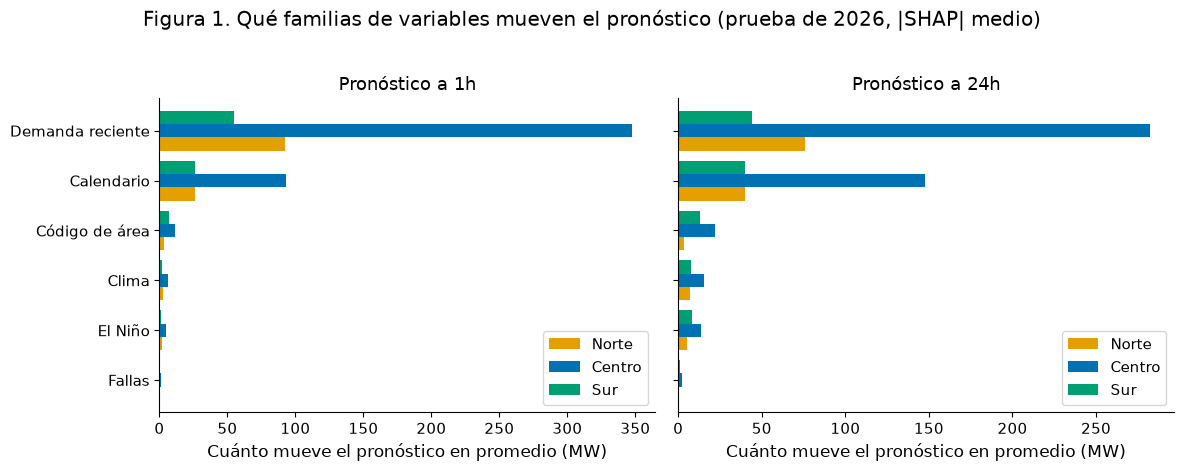

,Demanda reciente,Calendario,Código de área,Clima,El Niño,Fallas
Horizonte,,,,,,
1h,72.4 %,21.4 %,3.1 %,1.7 %,1.2 %,0.3 %
24h,55.1 %,31.2 %,5.3 %,4.1 %,3.7 %,0.6 %


In [5]:
filas = []
for h in HORIZONTES:
    por_periodo = por_familia(shap_mw[h])
    area = muestras[h]["area"].to_numpy()
    for a in AREAS:
        filas.append({"Horizonte": h, "Área": NOMBRES[a], **por_periodo[area == a].abs().mean().to_dict()})
familias = pd.DataFrame(filas).set_index(["Horizonte", "Área"])[list(FAMILIAS)]

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for eje, h in zip(ejes, HORIZONTES):
    familias.loc[h].T.iloc[::-1].plot.barh(ax=eje, color=[COLORES[a] for a in AREAS], width=0.8)
    eje.set_title(f"Pronóstico a {h}")
    eje.set_xlabel("Cuánto mueve el pronóstico en promedio (MW)")
    eje.legend(title="", loc="lower right")
fig.suptitle("Figura 1. Qué familias de variables mueven el pronóstico (prueba de 2026, |SHAP| medio)", y=1.02)
plt.tight_layout()
plt.show()
cuota = familias.groupby(level="Horizonte").sum()
cuota = 100 * cuota.div(cuota.sum(axis=1), axis=0)
display(familias.style.format("{:.1f}").set_caption("|SHAP| medio por familia (MW)"))
display(cuota.style.format("{:.1f} %").set_caption("Parte del movimiento total del pronóstico que aporta cada familia (las tres áreas)"))

#### Lectura del gráfico

- **La demanda reciente manda en los dos horizontes.** A 1 h mueve el pronóstico 347 MW en promedio en el Centro,
  frente a 93 MW del calendario; en las tres áreas, demanda reciente y calendario son el 93.8 % del movimiento. Para el
  negocio: el insumo crítico del pronóstico de la próxima hora es el dato de demanda de cada media hora; si llega tarde
  o mal, el pronóstico lo hereda.
- **A 24 h el calendario pasa del 21.4 % al 31.2 % del movimiento:** en el Centro sube de 93 a 148 MW, y en el Sur casi
  iguala a la demanda reciente (39.8 frente a 44.1 MW). Para el programa de mañana, qué día y qué hora es pesa casi tanto
  como lo que acaba de pasar, igual que en el razonamiento de un programador.
- **Clima, El Niño y fallas mueven poco:** juntos, el 3.2 % a 1 h y el 8.4 % a 24 h (en el Centro a 24 h: 15.7 MW el
  clima, 13.9 El Niño y 2.4 las fallas). Coincide con el notebook 03, donde quitarlas y reentrenar casi no cambia el
  error. Para el COES es una buena y una mala noticia: el pronóstico no depende de recibir a tiempo el clima o El Niño,
  pero tampoco anticipará un calor extremo que la demanda reciente todavía no muestre.

### Las variables, una por una: SHAP frente a la importancia por permutación

Para cada horizonte, las 10 variables que más mueven el pronóstico según SHAP (izquierda) y, en el mismo orden, cuánto
sube el MAE al desordenar cada una (derecha, permutación con tres repeticiones en la misma muestra). Las dos miden cosas
distintas: SHAP, cuánto **mueve el pronóstico**; la permutación, cuánto **daña el error** perderla. Por eso las cifras
no se comparan entre sí, pero el orden sí.

Importancia por permutación en 12 s


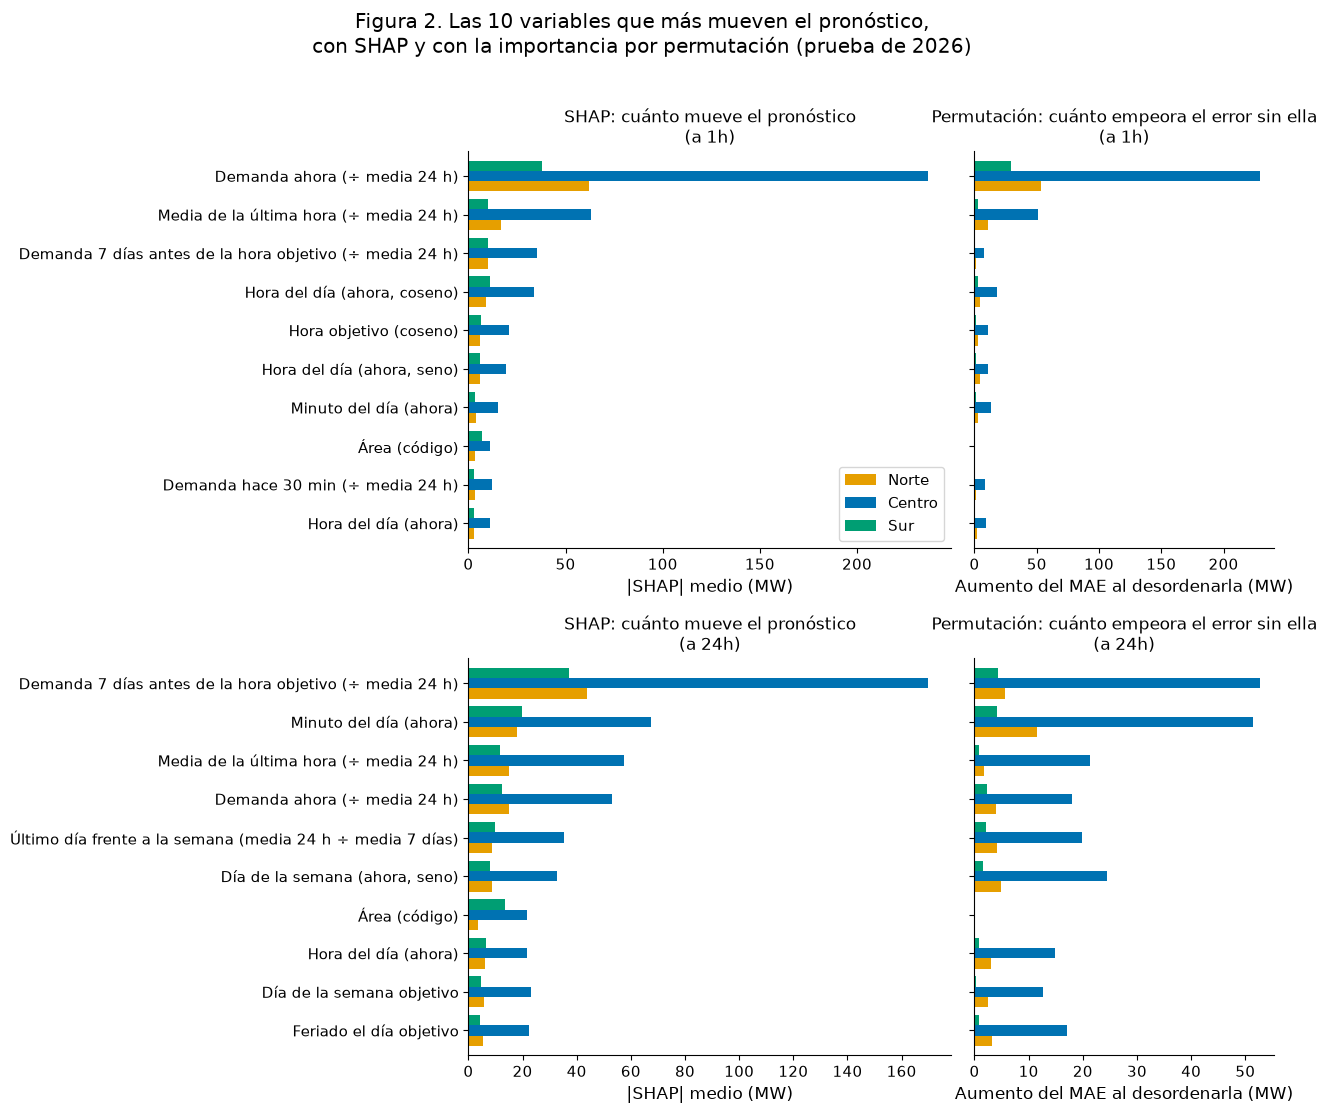

,SHAP 1h,Permutación 1h,SHAP 24h,Permutación 24h
Demanda 7 días antes de la hora objetivo (÷ media 24 h),3,11,1,2
Minuto del día (ahora),7,4,2,1
Media de la última hora (÷ media 24 h),2,2,3,6
Demanda ahora (÷ media 24 h),1,1,4,5
Último día frente a la semana (media 24 h ÷ media 7 días),21,22,5,4
"Día de la semana (ahora, seno)",26,18,6,3
Área (código),8,29,7,27
Hora del día (ahora),10,8,8,8
Día de la semana objetivo,25,20,9,10
Feriado el día objetivo,22,15,10,7


In [6]:
inicio, permutacion = time.time(), {}
for h in HORIZONTES:
    m = muestras[h]
    permutacion[h] = pd.DataFrame({
        NOMBRES[a]: pd.Series(permutation_importance(
            modelos[h], m.loc[m["area"] == a, COLS[h]], m.loc[m["area"] == a, "real"],
            scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEMILLA).importances_mean, index=COLS[h])
        for a in AREAS}).drop(index="media_24h")
print(f"Importancia por permutación en {time.time() - inicio:.0f} s")
shap_var = {h: pd.DataFrame({NOMBRES[a]: shap_mw[h][(muestras[h]["area"] == a).to_numpy()].abs().mean()
                             for a in AREAS}) for h in HORIZONTES}

TOP = 10
fig, ejes = plt.subplots(2, 2, figsize=(13, 11), gridspec_kw={"width_ratios": [1, 0.62]})
for fila, h in enumerate(HORIZONTES):
    orden = shap_var[h].mean(axis=1).sort_values(ascending=False).index[:TOP]
    for col, (tabla, titulo, etiqueta) in enumerate([
            (shap_var[h], "SHAP: cuánto mueve el pronóstico", "|SHAP| medio (MW)"),
            (permutacion[h], "Permutación: cuánto empeora el error sin ella", "Aumento del MAE al desordenarla (MW)")]):
        eje = ejes[fila, col]
        t = tabla.loc[orden].iloc[::-1]
        t.index = [llano(c) for c in t.index]
        t.plot.barh(ax=eje, color=[COLORES[a] for a in AREAS], width=0.8, legend=fila == 0 and col == 0)
        eje.set_title(f"{titulo}\n(a {h})", fontsize=12)
        eje.set_xlabel(etiqueta)
        if col == 1:
            eje.set_yticklabels([])  # mismo orden que el panel de la izquierda
fig.suptitle("Figura 2. Las 10 variables que más mueven el pronóstico,\ncon SHAP y con la importancia por permutación "
             "(prueba de 2026)", y=1.01)
plt.tight_layout()
plt.show()
puestos = pd.DataFrame({
    f"{metodo} {h}": tabla.mean(axis=1).rank(ascending=False).astype(int)
    for h in HORIZONTES for metodo, tabla in [("SHAP", shap_var[h]), ("Permutación", permutacion[h])]})
puestos.index = [llano(c) for c in puestos.index]
display(a_la_izquierda(puestos.sort_values("SHAP 24h").head(10).style)
        .set_caption("Puesto de cada variable (1 = la más importante; media de las tres áreas), por SHAP a 24 h"))
PARES = [("1h", "Area_t"), ("1h", "Area_media_1h"), ("1h", "Area_semana_pasada"), ("24h", "Area_semana_pasada"),
         ("24h", "MinuteOfDay"), ("24h", "FeriadoObjetivo"), ("24h", "nino12_ssta"), ("24h", "temp_objetivo")]
display(pd.DataFrame([{"Horizonte": h, "Variable": llano(c),
                       **{f"SHAP · {NOMBRES[a]}": shap_var[h].loc[c, NOMBRES[a]] for a in AREAS},
                       **{f"Permutación · {NOMBRES[a]}": permutacion[h].loc[c, NOMBRES[a]] for a in AREAS}}
                      for h, c in PARES]).set_index(["Horizonte", "Variable"])
        .style.format("{:.1f}").set_table_styles(IZQUIERDA, overwrite=False).set_caption("Ocho lecturas con los dos métodos (MW): SHAP mueve el pronóstico, la permutación empeora el MAE"))

#### Lectura del gráfico

- **A 1 h, una sola variable hace casi todo:** «Demanda ahora (÷ media 24 h)» es la primera con los dos métodos; en el
  Centro mueve el pronóstico 236.8 MW y desordenarla sube el MAE 229.1 MW. El pronóstico de la próxima hora es,
  en el fondo, «la demanda de ahora, corregida por la hora del día».
- **A 24 h mandan la semana pasada a la misma hora y la hora del día:** puestos 1 y 2 con SHAP, 2 y 1 con la
  permutación (en el Centro, 169.9 MW de SHAP para la semana pasada). El programa del día siguiente se arma con lo que
  pasó hace una semana a esa hora: el mismo atajo de un programador con experiencia, y la referencia ingenua más difícil
  de vencer en el Norte y el Centro.
- **Los dos métodos coinciden en lo esencial y discrepan donde se espera.** La permutación castiga poco a lo redundante:
  la semana pasada es tercera con SHAP a 1 h y undécima con la permutación, porque la demanda de ahora la reemplaza. El
  código de área queda en los puestos 29 y 27 con la permutación porque, dentro de un área, no cambia. Y el feriado sube con la
  permutación (puesto 7 frente a 10): aparece pocas veces, pero equivocarse en esos días cuesta mucho MAE.
- **Para el negocio:** que dos métodos distintos pongan arriba las mismas variables, y que sean las que usaría un
  programador, es evidencia de que el modelo aprendió patrones reales del sistema y no artefactos de los datos.

### Hacia dónde empuja cada variable

Cada punto es un periodo de la muestra de 2026 a 24 h (las tres áreas). La posición horizontal es cuánto movió el
pronóstico esa variable (a la derecha lo sube, a la izquierda lo baja) y el color, el valor de la variable (azul
oscuro, bajo; amarillo, alto; escala *cividis*, legible con daltonismo). A 24 h, la hora «de ahora» es la misma hora
del día que se pronostica.

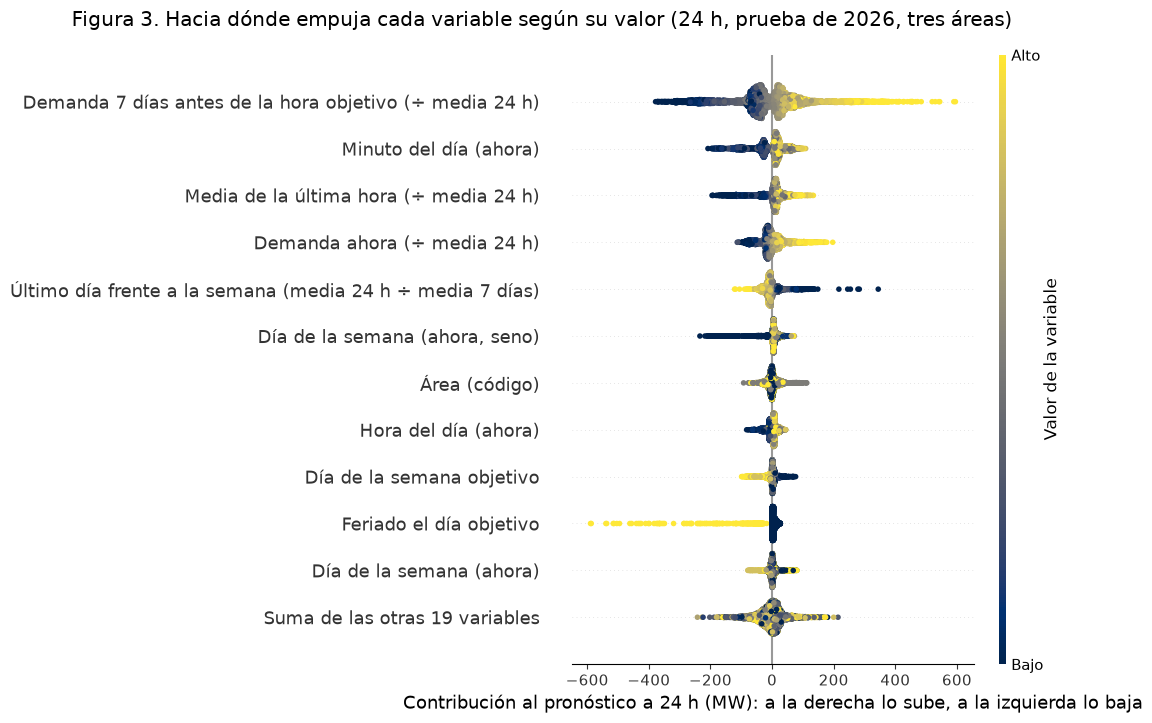

«Feriado el día objetivo» = 1 en 240 de 6,000 periodos de la muestra; ahí resta en promedio 131 MW (hasta 589). Cuando vale 0, mueve en promedio 5.7 MW.


In [7]:
v, m = shap_mw["24h"], muestras["24h"]
explicacion = shap.Explanation(values=v.to_numpy(), base_values=m["base_mw"].to_numpy(),
                               data=m[list(v.columns)].to_numpy(dtype=float),
                               feature_names=[llano(c) for c in v.columns])
plt.figure(figsize=(11, 7))
shap.plots.beeswarm(explicacion, max_display=12, color=plt.get_cmap("cividis"), show=False, plot_size=None,
                    color_bar_label="Valor de la variable")
fig = plt.gcf()
ejes_bee = fig.axes[0]
ejes_bee.set_yticklabels([e.get_text().replace("Sum of", "Suma de las otras").replace("other features", "variables")
                          for e in ejes_bee.get_yticklabels()])
ejes_bee.set_xlabel("Contribución al pronóstico a 24 h (MW): a la derecha lo sube, a la izquierda lo baja")
for eje in fig.axes[1:]:  # la barra de color de shap viene en inglés
    if {e.get_text() for e in eje.get_yticklabels()} == {"Low", "High"}:
        eje.set_yticklabels(["Bajo", "Alto"])
plt.tight_layout()
fig.suptitle("Figura 3. Hacia dónde empuja cada variable según su valor (24 h, prueba de 2026, tres áreas)", y=1.03)
plt.show()
feriado = v["FeriadoObjetivo"][m["FeriadoObjetivo"] == 1]
print(f"«Feriado el día objetivo» = 1 en {len(feriado)} de {len(m):,} periodos de la muestra; ahí resta en promedio "
      f"{-feriado.mean():.0f} MW (hasta {-feriado.min():.0f}). Cuando vale 0, mueve en promedio "
      f"{v['FeriadoObjetivo'][m['FeriadoObjetivo'] == 0].abs().mean():.1f} MW.")

#### Lectura del gráfico

- **La semana pasada empuja en las dos direcciones, de unos −380 a +600 MW:** si hace una semana a esa hora la demanda
  estuvo alta frente al último día (amarillo), el pronóstico sube; si estuvo baja (azul), baja. Es el mecanismo que trae
  el perfil semanal (lunes hábil, sábado, domingo) al programa del día siguiente.
- **El feriado funciona como un interruptor:** cuando vale 1 (240 de los 6,000 periodos de la muestra) resta 131 MW en
  promedio y hasta 589 MW; cuando vale 0, apenas 5.7 MW. En la Figura 2 queda décimo porque hay pocos feriados, pero en
  esos días decide el pronóstico, y es donde aparece el peor error del año (Figura 5).
- **«Último día frente a la semana» corrige el punto de partida:** cuando el último día vino bajo frente a la semana
  (azul: después de un domingo o de un feriado), suma hasta unos 340 MW, para no arrastrar un día atípico al siguiente.
  Y el día de la semana (seno) muy bajo, que corresponde a emitir un sábado y pronosticar un domingo, resta hasta unos
  240 MW. Para el programador, el modelo «sabe» que el domingo se consume menos y que el lunes se recupera.

## 2.3 Casos individuales: por qué el modelo dijo lo que dijo

Explicar un pronóstico concreto es lo que necesita el operador cuando un número le llama la atención. Elegimos tres
casos de 2026 a 24 h con una regla escrita **antes** de mirar sus explicaciones:

1. **Un pico bien pronosticado:** entre los 20 periodos de más demanda del Centro en 2026, el de menor error.
2. **El peor error de 2026:** el periodo con mayor error absoluto en las tres áreas.
3. **Un día de El Niño:** en el Norte, en agosto de 2026 (el pico del episodio), el periodo en que las variables de El
   Niño más movieron el pronóstico.

Antes, un control de datos: dejamos fuera los **traspasos de media hora entre áreas**, periodos en que la demanda de un
área salta más de 10 % y vuelve en la media hora siguiente mientras el SEIN no se mueve. Es demanda que el anexo del
COES asigna a otra área durante media hora, no consumo, y ningún modelo puede anticiparla.

**Cómo leer un *waterfall*.** Abajo está el punto de partida (el nivel del último día); cada barra suma (bermellón) o
resta (azul) MW, de la variable que más mueve a la que menos; arriba queda el pronóstico. A la izquierda de cada nombre
va el valor que tenía la variable en ese periodo, y la línea punteada marca la demanda real.

In [8]:
def saltos_aislados(area, umbral=0.10):
    """Periodos en que la demanda del área sube o baja más que `umbral` en media hora y vuelve en la siguiente."""
    s = corrida.demanda.set_index("DateTime")[area]
    antes, despues = s / s.shift(1) - 1, s.shift(-1) / s - 1
    marca = (antes.abs() > umbral) & (despues.abs() > umbral) & (np.sign(antes) != np.sign(despues))
    return set(s.index[marca & (s.index >= "2026-01-01")])


SALTOS = {a: saltos_aislados(a) for a in AREAS}
print("Traspasos de media hora entre áreas en 2026 (fuera de la elección):",
      {NOMBRES[a]: len(s) for a, s in SALTOS.items()})
p24 = prueba["24h"].assign(salto=lambda t: [o in SALTOS[a] for o, a in zip(t["objetivo"], t["area"])])
limpio = p24[~p24["salto"]]
CASO_PICO = limpio[limpio["area"] == "CENTRO"].nlargest(20, "real")["error"].abs().idxmin()
CASO_PEOR = limpio["error"].abs().idxmax()
norte_agosto = limpio[(limpio["area"] == "NORTE") & (limpio["objetivo"].dt.month == 8)]
nino_agosto = por_familia(explicar("24h", norte_agosto)[0])["El Niño"]
CASO_NINO = nino_agosto.abs().idxmax()
casos = p24.loc[[CASO_PICO, CASO_PEOR, CASO_NINO]].assign(
    caso=["1. Pico bien pronosticado", "2. Peor error de 2026", "3. Día de El Niño"],
    error_pct=lambda t: 100 * t["error"] / t["real"]).set_index("caso")
display(casos[["area", "objetivo", "real", "pred", "error", "error_pct", "FeriadoObjetivo", "icen", "nino12_ssta",
               "temp_objetivo"]].assign(area=lambda t: t["area"].map(NOMBRES),
                                        objetivo=lambda t: t["objetivo"].dt.strftime("%d/%m/%Y %H:%M")).rename(columns={"area": "Área", "objetivo": "Hora objetivo", "real": "Real (MW)",
                                                 "pred": "Pronóstico (MW)", "error": "Error (MW)", "error_pct": "Error (%)",
                                                 "FeriadoObjetivo": "Feriado", "icen": "ICEN", "nino12_ssta": "Niño 1+2",
                                                 "temp_objetivo": "Temp. pronosticada (°C)"})
        .style.format(precision=1).set_table_styles(IZQUIERDA, overwrite=False).set_caption("Los tres casos, pronosticados 24 h antes (excluidos los traspasos de media hora entre áreas)"))
print("MAE a 24 h en 2026, para comparar:", {NOMBRES[a]: round(e, 1) for a, e in p24.groupby("area")["error"].apply(lambda e: e.abs().mean()).items()})


def cascada(indice, titulo, h="24h", max_display=10):
    """Waterfall de SHAP en MW: del punto de partida (base × media de 24 h) al pronóstico, variable por variable."""
    filas = prueba[h].loc[[indice]]
    v, base, pred = explicar(h, filas)
    e = shap.Explanation(values=v.iloc[0].to_numpy(), base_values=float(base[0]),
                         data=filas[VARIABLES].iloc[0].to_numpy(dtype=float), feature_names=[llano(c) for c in VARIABLES])
    shap.plots.waterfall(e, max_display=max_display, show=False)
    fig = plt.gcf()
    fig.set_size_inches(11, 6)
    real = float(filas["real"].iloc[0])
    izquierda, derecha = fig.axes[0].get_xlim()
    margen = 0.05 * (max(derecha, real) - min(izquierda, real))
    for eje in fig.axes:
        eje.set_xlim(min(izquierda, real - margen), max(derecha, real + margen))
    for eje in fig.axes:  # shap rotula en inglés: punto de partida, pronóstico y «otras variables»
        textos = [t.get_text() for t in eje.get_xticklabels()]
        if textos and "E[f(X)]" in textos[0]:
            eje.set_xticks(eje.get_xticks(), ["\nPunto de partida", f"\n = {base[0]:,.0f} MW"], fontsize=11)
        elif textos and "f(x)" in textos[0]:
            eje.set_xticks(eje.get_xticks(), ["Pronóstico", f" = {pred[0]:,.0f} MW"], fontsize=11)
        if textos and ("E[f(X)]" in textos[0] or "f(x)" in textos[0]):  # el nombre a la izquierda, la cifra a la derecha
            nombre, cifra = eje.get_xticklabels()
            nombre.set_ha("right")
            cifra.set_ha("left")
            cifra.set_color("#777777")
        etiquetas = eje.get_yticklabels()
        if any("other features" in t.get_text() for t in etiquetas):
            colores = [t.get_color() for t in etiquetas]
            eje.set_yticks(eje.get_yticks(), [re.sub(r"(\d+) other features", r"otras \1 variables", t.get_text())
                                              for t in etiquetas])
            for t, color in zip(eje.get_yticklabels(), colores):
                t.set_color(color)
    fig.axes[0].axvline(real, color="black", ls=":", lw=2, label=f"Real: {real:,.0f} MW")
    fig.axes[0].legend(loc="lower right", fontsize=11)
    fig.axes[0].set_title(titulo, pad=28)
    plt.show()
    print(f"Punto de partida (base × media de 24 h): {base[0]:,.0f} MW · pronóstico: {pred[0]:,.0f} MW · "
          f"real: {real:,.0f} MW · error: {real - pred[0]:+,.0f} MW")
    return tabla_contribuciones(v.iloc[0], filas.iloc[0], top=max_display - 1)


def tabla_contribuciones(fila_mw, datos_fila, top, titulo=None):
    """Las `top` variables que más mueven un pronóstico, con su valor y su contribución en MW, y el resto sumado."""
    tabla = contribuciones(fila_mw, datos_fila, top=top)
    tabla["variable"] = [llano(c) for c in tabla["variable"]]
    tabla.columns = ["Variable", "Valor en ese periodo", "Contribución (MW)"]
    estilo = (tabla.style.hide(axis="index").format({"Valor en ese periodo": "{:.3f}", "Contribución (MW)": "{:+.1f}"},
                                                    na_rep="")
              .set_properties(subset=["Variable"], **{"text-align": "left"}))
    return estilo.set_caption(titulo) if titulo else estilo


def titulo(indice, figura, que):
    f = p24.loc[indice]
    return f"Figura {figura}. {que}: {NOMBRES[f['area']]}, {f['objetivo']:%d/%m/%Y %H:%M}, pronosticado 24 h antes"

Traspasos de media hora entre áreas en 2026 (fuera de la elección): {'Norte': 3, 'Centro': 1, 'Sur': 3}


,Área,Hora objetivo,Real (MW),Pronóstico (MW),Error (MW),Error (%),Feriado,ICEN,Niño 1+2,Temp. pronosticada (°C)
caso,,,,,,,,,,
1. Pico bien pronosticado,Centro,24/02/2026 15:00,5379.8,5367.1,12.7,0.2,0,-0.5,0.8,28.7
2. Peor error de 2026,Centro,29/06/2026 13:00,4366.6,3591.0,775.7,17.8,1,1.3,3.1,25.6
3. Día de El Niño,Norte,02/08/2026 00:30,991.3,1004.2,-12.9,-1.3,0,2.0,3.6,24.0


MAE a 24 h en 2026, para comparar: {'Centro': 85.3, 'Norte': 32.8, 'Sur': 51.0}


### Caso 1: un pico de demanda bien pronosticado

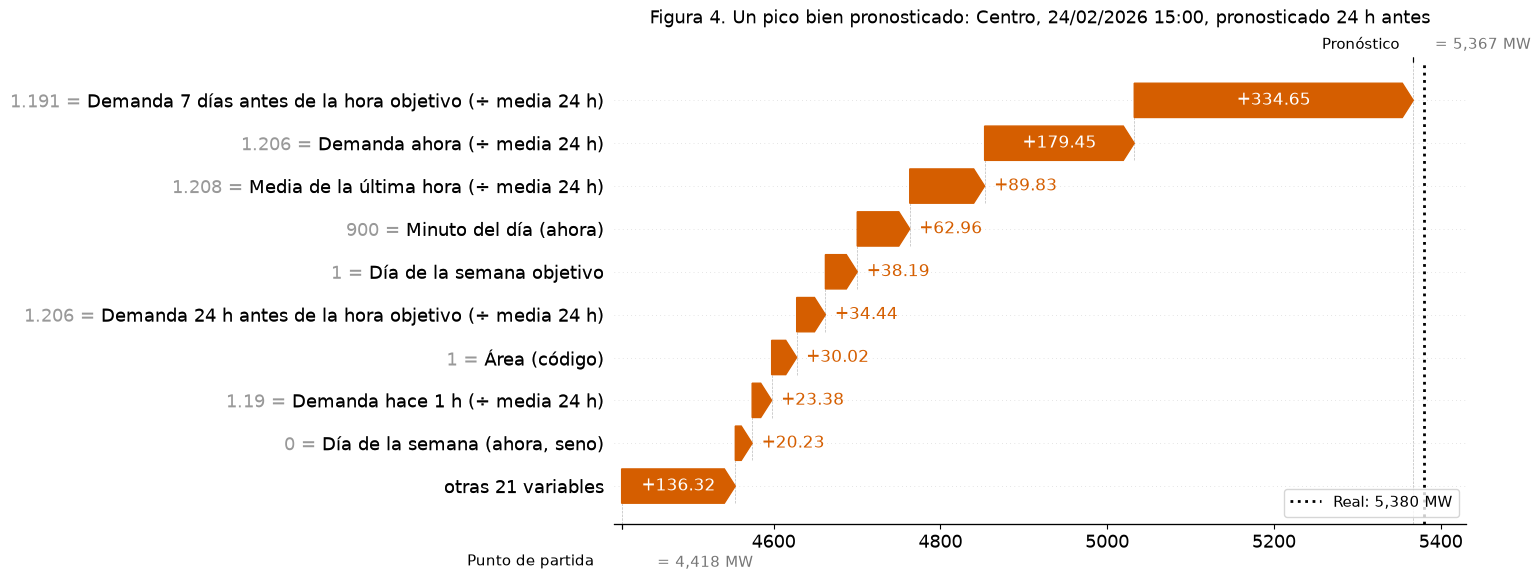

Punto de partida (base × media de 24 h): 4,418 MW · pronóstico: 5,367 MW · real: 5,380 MW · error: +13 MW


Variable,Valor en ese periodo,Contribución (MW)
Demanda 7 días antes de la hora objetivo (÷ media 24 h),1.191,+334.6
Demanda ahora (÷ media 24 h),1.206,+179.4
Media de la última hora (÷ media 24 h),1.208,+89.8
Minuto del día (ahora),900.000,+63.0
Día de la semana objetivo,1.000,+38.2
Demanda 24 h antes de la hora objetivo (÷ media 24 h),1.206,+34.4
Área (código),1.000,+30.0
Demanda hace 1 h (÷ media 24 h),1.190,+23.4
"Día de la semana (ahora, seno)",0.000,+20.2
otras 21 variables,,+136.3


In [9]:
display(cascada(CASO_PICO, titulo(CASO_PICO, 4, "Un pico bien pronosticado")))

#### Lectura del gráfico

- **Un pico de verano pronosticado con 13 MW de error.** El martes 24 de febrero de 2026 a las 15:00 el Centro demandó
  5,380 MW, uno de sus 20 periodos más altos del año; el modelo había dicho 5,367 MW un día antes: 0.2 % de error,
  frente a 85.3 MW de error medio del Centro a 24 h.
- **Lo arma con el ciclo semanal y diario, no con el clima.** Desde el nivel del último día (4,418 MW), la semana pasada
  a esa hora (19 % sobre la media de 24 h) suma 335 MW; la demanda al emitir el pronóstico, el lunes a las 15:00 (21 %
  sobre la media), 179 MW; la media de esa última hora, 90 MW; las 15:00, 63 MW; y que el día objetivo sea martes,
  38 MW. Ninguna variable de clima está entre las nueve primeras, aun con 28.7 °C pronosticados.
- **Para el operador:** el pico se anticipa porque el lunes y el martes anterior ya habían sido altos a esa hora. El
  modelo acierta los picos que se vienen gestando; uno que llegue de golpe, sin aviso en la demanda reciente (una ola
  de calor repentina), es el que se le escaparía.

### Caso 2: el peor error de 2026

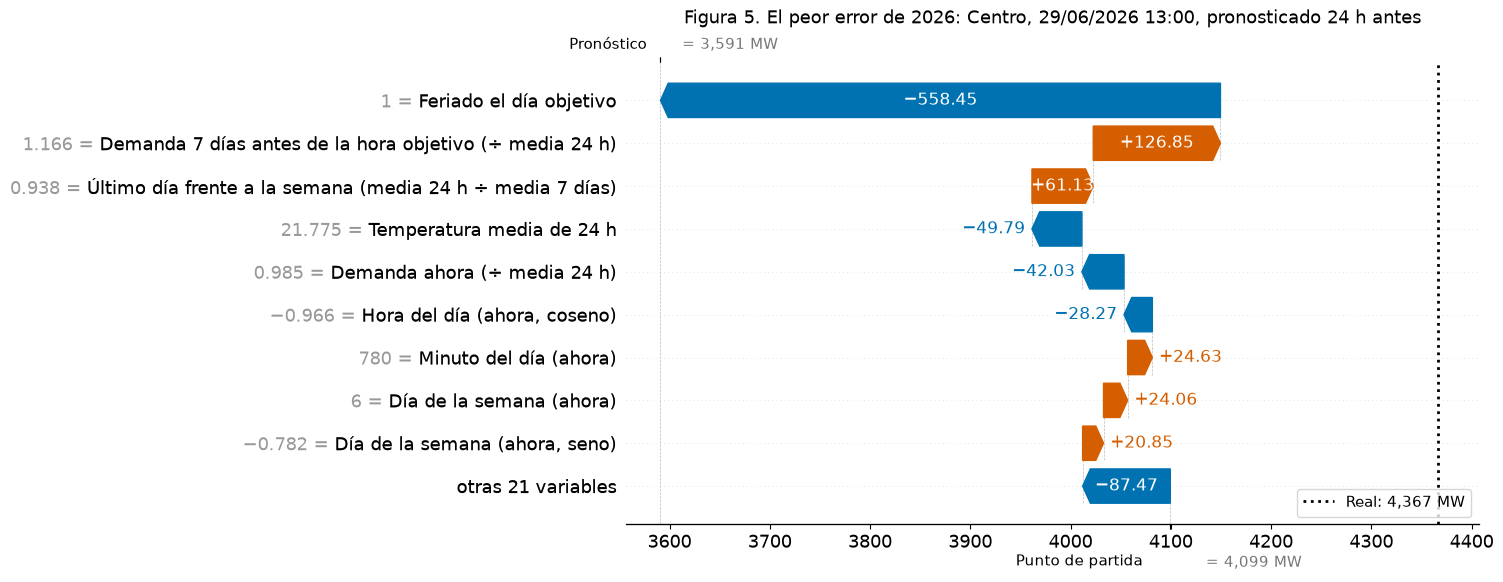

Punto de partida (base × media de 24 h): 4,099 MW · pronóstico: 3,591 MW · real: 4,367 MW · error: +776 MW


Variable,Valor en ese periodo,Contribución (MW)
Feriado el día objetivo,1.000,-558.5
Demanda 7 días antes de la hora objetivo (÷ media 24 h),1.166,+126.8
Último día frente a la semana (media 24 h ÷ media 7 días),0.938,+61.1
Temperatura media de 24 h,21.775,-49.8
Demanda ahora (÷ media 24 h),0.985,-42.0
"Hora del día (ahora, coseno)",-0.966,-28.3
Minuto del día (ahora),780.000,+24.6
Día de la semana (ahora),6.000,+24.1
"Día de la semana (ahora, seno)",-0.782,+20.8
otras 21 variables,,-87.5


,29/06/2026
Real en el periodo (MW),4366.6
Pronóstico (MW),3591.0
"Misma hora, el día anterior (domingo) (MW)",4027.8
"Misma hora, una semana antes (lunes hábil) (MW)",4771.3
"Error medio de todo ese día, a 24 h (MW)",387.0


Feriados entre semana en el entrenamiento (2016-2024): 87; en lunes: 13


In [10]:
display(cascada(CASO_PEOR, titulo(CASO_PEOR, 5, "El peor error de 2026")))
f = p24.loc[CASO_PEOR]
serie = corrida.demanda.set_index("DateTime")[f["area"]]
dia = f["objetivo"].normalize()
display(pd.Series({
    "Real en el periodo (MW)": f["real"],
    "Pronóstico (MW)": f["pred"],
    "Misma hora, el día anterior (domingo) (MW)": serie.get(f["objetivo"] - pd.Timedelta(days=1)),
    "Misma hora, una semana antes (lunes hábil) (MW)": serie.get(f["objetivo"] - pd.Timedelta(days=7)),
    "Error medio de todo ese día, a 24 h (MW)": p24[(p24["area"] == f["area"]) & (p24["objetivo"].dt.normalize() == dia)]["error"].mean(),
}).round(1).to_frame(f"{dia:%d/%m/%Y}"))
feriados = pd.DatetimeIndex(pd.to_datetime(corrida.feriados))
entre_semana = feriados[(feriados.year <= 2024) & (feriados.day_of_week < 5)]
print(f"Feriados entre semana en el entrenamiento (2016-2024): {len(entre_semana)}; en lunes: "
      f"{(entre_semana.day_of_week == 0).sum()}")

#### Lectura del gráfico

- **El peor error de 2026 es un feriado: 776 MW (17.8 %).** El lunes 29 de junio (San Pedro y San Pablo) a las 13:00 el
  Centro demandó 4,367 MW y el modelo había dicho 3,591, menos incluso que el domingo anterior a esa hora (4,028 MW). En
  todo ese día, el error medio fue de 387 MW.
- **Por qué: descontó el feriado dos veces.** «Feriado el día objetivo» resta 558 MW, pero el punto de partida
  (4,099 MW) ya era bajo, porque la media de las últimas 24 h era la de un domingo. El modelo aprendió el efecto del
  feriado sobre todo con feriados que siguen a un día hábil (de los 87 feriados entre semana de 2016 a 2024, solo 13
  cayeron en lunes) y lo aplicó entero sobre un día que ya venía bajo. La semana pasada (un lunes hábil, 4,771 MW) y el
  último día bajo frente a la semana empujan hacia arriba (+127 y +61 MW), pero no alcanzan.
- **Qué hacer con esto:** los feriados en lunes son el punto ciego del programa del día siguiente. La mejora más directa
  es una variable que diga si el día anterior fue domingo o feriado (o medir el feriado frente a un domingo); mientras
  tanto, el programador debería revisar a mano esos días. Sin SHAP, este error parecería mala suerte; con SHAP, es una
  regla que se puede corregir.

### El mismo caso con LIME, como contraste

LIME inventa 5,000 variantes del caso (muestrea cada variable de la distribución del entrenamiento, con la media de
24 h fija en la del caso), le pide al XGBoost su pronóstico para cada una y ajusta un modelo lineal que da más peso a
las variantes más parecidas al caso. Lo corremos con tres semillas para ver si su respuesta es estable.

LIME, semilla 0: R² local 0.38 · pronóstico del modelo 3,591 MW · del modelo lineal local 4,147 MW


LIME, semilla 1: R² local 0.37 · pronóstico del modelo 3,591 MW · del modelo lineal local 4,109 MW
LIME, semilla 2: R² local 0.35 · pronóstico del modelo 3,591 MW · del modelo lineal local 4,156 MW
LIME en 0 s


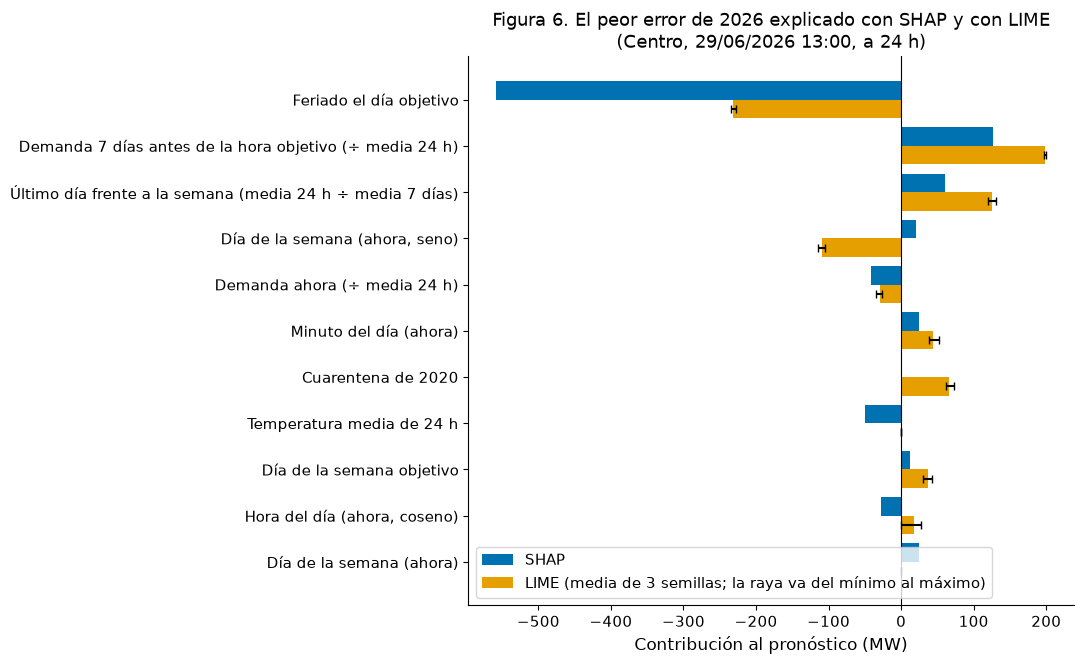

,SHAP (MW),"LIME, media de 3 semillas (MW)",LIME mín.,LIME máx.
Día de la semana (ahora),+24.1,+0.0,+0.0,+0.0
"Hora del día (ahora, coseno)",-28.3,+18.0,+0.0,+27.4
Día de la semana objetivo,+12.4,+36.5,+30.6,+41.9
Temperatura media de 24 h,-49.8,+0.0,+0.0,+0.0
Cuarentena de 2020,-0.6,+66.4,+62.5,+73.1
Minuto del día (ahora),+24.6,+43.8,+38.9,+52.0
Demanda ahora (÷ media 24 h),-42.0,-29.2,-34.1,-25.9
"Día de la semana (ahora, seno)",+20.8,-109.2,-114.5,-105.0
Último día frente a la semana (media 24 h ÷ media 7 días),+61.1,+125.8,+119.6,+130.8
Demanda 7 días antes de la hora objetivo (÷ media 24 h),+126.8,+199.0,+196.8,+200.3


,semilla 0,semilla 1,semilla 2
1,Feriado el día objetivo=1: -234 MW,Feriado el día objetivo=1: -235 MW,Feriado el día objetivo=1: -227 MW
2,Demanda 7 días antes de la hora objetivo (÷ media 24 h) > 1.08: +200 MW,Demanda 7 días antes de la hora objetivo (÷ media 24 h) > 1.08: +200 MW,Demanda 7 días antes de la hora objetivo (÷ media 24 h) > 1.08: +197 MW
3,Último día frente a la semana (media 24 h ÷ media 7 días) <= 0.98: +127 MW,Último día frente a la semana (media 24 h ÷ media 7 días) <= 0.98: +131 MW,Último día frente a la semana (media 24 h ÷ media 7 días) <= 0.98: +120 MW
4,"Día de la semana (ahora, seno) <= -0.78: -115 MW","Día de la semana (ahora, seno) <= -0.78: -108 MW","Día de la semana (ahora, seno) <= -0.78: -105 MW"
5,Cuarentena de 2020=0: +64 MW,Cuarentena de 2020=0: +62 MW,Cuarentena de 2020=0: +73 MW
6,690.00 < Minuto del día (ahora) <= 1050.00: +52 MW,690.00 < Minuto del día (ahora) <= 1050.00: +39 MW,Día de la semana objetivo=0: +42 MW
7,0.94 < Demanda ahora (÷ media 24 h) <= 1.00: -34 MW,Día de la semana objetivo=0: +37 MW,690.00 < Minuto del día (ahora) <= 1050.00: +41 MW
8,Día de la semana objetivo=0: +31 MW,Anomalía del mar en Niño 1+2 > 0.60: -32 MW,"Hora del día (ahora, coseno) <= -0.71: +27 MW"
9,"Hora del día (ahora, coseno) <= -0.71: +27 MW",0.94 < Demanda ahora (÷ media 24 h) <= 1.00: -28 MW,0.94 < Demanda ahora (÷ media 24 h) <= 1.00: -26 MW
10,11.00 < Hora del día (ahora) <= 17.00: +26 MW,11.00 < Hora del día (ahora) <= 17.00: +26 MW,11.00 < Hora del día (ahora) <= 17.00: +24 MW


In [11]:
h = "24h"
caso = prueba[h].loc[CASO_PEOR]
entrenamiento = tramo(datos[h], "entrenamiento").sample(5000, random_state=SEMILLA)
CATEGORICAS = ["area_cod", "DayOfWeek", "DiaSemanaObjetivo", "FinDeSemanaObjetivo", "FeriadoObjetivo", "Cuarentena"]


def pronosticar(Z, escala=float(caso["media_24h"])):
    """El modelo en MW para las filas que inventa LIME: la escala (media de 24 h) queda fija, la del caso."""
    return modelos[h].predict(pd.DataFrame(Z, columns=VARIABLES).assign(media_24h=escala)[COLS[h]])


NOMBRE_VARIABLE = r"\b(" + "|".join(sorted(VARIABLES, key=len, reverse=True)) + r")\b"
corridas_lime, condiciones = [], {}
inicio = time.time()
for semilla in range(3):
    explicador = LimeTabularExplainer(entrenamiento[VARIABLES].to_numpy(dtype=float), mode="regression",
                                      feature_names=VARIABLES, categorical_features=[VARIABLES.index(c) for c in CATEGORICAS],
                                      discretize_continuous=True, random_state=semilla)
    exp = explicador.explain_instance(caso[VARIABLES].to_numpy(dtype=float), pronosticar, num_features=10,
                                      num_samples=5000)
    corridas_lime.append(pd.Series(dict(exp.as_map()[1])).rename(index=dict(enumerate(VARIABLES))))
    condiciones[f"semilla {semilla}"] = [re.sub(NOMBRE_VARIABLE, lambda m: llano(m.group(1)), f"{c}: {w:+.0f} MW")
                                         for c, w in exp.as_list()]
    print(f"LIME, semilla {semilla}: R² local {exp.score:.2f} · pronóstico del modelo {exp.predicted_value:,.0f} MW · "
          f"del modelo lineal local {exp.local_pred[0]:,.0f} MW")
print(f"LIME en {time.time() - inicio:.0f} s")
lime_mw = pd.concat(corridas_lime, axis=1).fillna(0.0)
shap_caso = explicar(h, prueba[h].loc[[CASO_PEOR]])[0].iloc[0]
elegidas = list(dict.fromkeys(list(shap_caso.abs().nlargest(8).index) + list(lime_mw.mean(axis=1).abs().nlargest(8).index)))
lime_elegidas = lime_mw.reindex(elegidas).fillna(0.0)  # 0: LIME no eligió esa variable entre sus 10
comparacion = pd.DataFrame({"SHAP (MW)": shap_caso[elegidas], "LIME, media de 3 semillas (MW)": lime_elegidas.mean(axis=1),
                            "LIME mín.": lime_elegidas.min(axis=1), "LIME máx.": lime_elegidas.max(axis=1)})
comparacion = comparacion.loc[comparacion["SHAP (MW)"].abs().add(comparacion["LIME, media de 3 semillas (MW)"].abs())
                              .sort_values().index]

fig, eje = plt.subplots(figsize=(11, 6.8))
y = np.arange(len(comparacion))
eje.barh(y + 0.2, comparacion["SHAP (MW)"], height=0.4, color="#0072B2", label="SHAP")
media = comparacion["LIME, media de 3 semillas (MW)"]
eje.barh(y - 0.2, media, height=0.4, color="#E69F00", label="LIME (media de 3 semillas; la raya va del mínimo al máximo)",
         xerr=[media - comparacion["LIME mín."], comparacion["LIME máx."] - media], ecolor="black", capsize=3)
eje.set_yticks(y, [llano(c) for c in comparacion.index])
eje.axvline(0, color="black", lw=0.8)
eje.set_xlabel("Contribución al pronóstico (MW)")
eje.set_title("Figura 6. El peor error de 2026 explicado con SHAP y con LIME\n(Centro, 29/06/2026 13:00, a 24 h)")
eje.legend(loc="lower left")
plt.tight_layout()
plt.show()
display(a_la_izquierda(comparacion.rename(index=llano).style.format("{:+.1f}")).set_caption("SHAP y LIME para el mismo pronóstico (MW)"))
display(a_la_izquierda(pd.DataFrame(condiciones, index=range(1, 11)).style.format(escape="html"), list(condiciones))
        .set_caption("Lo que dice LIME, con sus reglas: «condición: MW» (las 10 primeras de cada semilla)"))

#### Lectura del gráfico

- **LIME y SHAP cuentan la misma historia principal:** con las tres semillas, el feriado es lo que más resta y la
  semana pasada y el último día bajo frente a la semana son lo que más suma. Que dos métodos con supuestos distintos
  señalen al feriado refuerza el diagnóstico del caso 2.
- **Pero LIME es mucho menos fiel:** su modelo lineal explica solo entre el 35 % y el 38 % de la variación alrededor
  del caso (R² local) y, en el propio caso, pronostica entre 4,109 y 4,156 MW cuando el XGBoost dice 3,591: no
  reproduce la predicción que quiere explicar. Por eso le da al feriado entre −227 y −235 MW, menos de la mitad de los
  −558 de SHAP, que sí suma exacto.
- **Y depende de cómo inventa los vecinos:** le atribuye entre +62 y +73 MW a «no estar en cuarentena» (SHAP: −0.6),
  porque entre sus variantes aparecen periodos de la cuarentena de 2020, que bajan la demanda; y le da al día de la
  semana (seno) el signo contrario que SHAP (−109 frente a +21 MW). Para el negocio, son contribuciones sin sentido en
  junio de 2026.
- **Conclusión de la comparación:** para este XGBoost usamos SHAP como explicación oficial (exacta y estable) y LIME
  solo como chequeo. Si las dos discrepan, la discrepancia es una señal para mirar el caso con cuidado, no una segunda
  verdad.

### Caso 3: un día de El Niño en el Norte

In [12]:
display(a_la_izquierda(pd.Series({
    "Periodos del Norte en agosto de 2026": f"{len(nino_agosto):,}",
    "Contribución media de El Niño (MW)": f"{nino_agosto.mean():+.1f}",
    "Contribución mínima y máxima (MW)": f"{nino_agosto.min():+.1f} y {nino_agosto.max():+.1f}",
    "Demanda media del Norte en agosto (MW)": f"{norte_agosto['real'].mean():,.1f}",
    "Error del caso 3 (MW)": f"{p24.loc[CASO_NINO, 'error']:+.1f}"}).to_frame("El Niño en el Norte, agosto de 2026").style))
display(tabla_contribuciones(explicar("24h", prueba["24h"].loc[[CASO_NINO]])[0].iloc[0], prueba["24h"].loc[CASO_NINO], top=6,
                             titulo=f"Caso 3: Norte, {p24.loc[CASO_NINO, 'objetivo']:%d/%m/%Y %H:%M}, las seis variables que más lo movieron"))

,"El Niño en el Norte, agosto de 2026"
Periodos del Norte en agosto de 2026,"1,486"
Contribución media de El Niño (MW),-6.7
Contribución mínima y máxima (MW),-19.7 y +10.2
Demanda media del Norte en agosto (MW),"1,130.8"
Error del caso 3 (MW),-12.9


Variable,Valor en ese periodo,Contribución (MW)
Demanda 7 días antes de la hora objetivo (÷ media 24 h),0.972,-17.8
Media de la última hora (÷ media 24 h),0.892,-17.6
Anomalía del mar en Niño 1+2,3.600,-17.1
Minuto del día (ahora),30.000,-17.1
Demanda ahora (÷ media 24 h),0.883,-14.3
"Día de la semana (ahora, seno)",-0.975,-11.0
otras 24 variables,,-53.5


#### Lectura de las tablas

- **En pleno El Niño costero, El Niño mueve poco el pronóstico:** en agosto de 2026 su familia aporta en promedio
  −6.7 MW (entre −19.7 y +10.2) al pronóstico del Norte, que ese mes demandó 1,131 MW en promedio. En el periodo en que
  más pesó (domingo 2 de agosto a las 00:30, con el Niño 1+2 en +3.6 °C) resta 17 MW, y el pronóstico acierta con
  13 MW de error.
- **Y empuja hacia abajo:** el modelo aprendió El Niño de los episodios del entrenamiento, y en el de 2017 la demanda
  del Norte cayó entre 6 % y 7 % (notebook 01). En 2026 crece: si el pronóstico dependiera de El Niño, se equivocaría de
  dirección.
- **El nivel lo trae la escala:** el punto de partida (la media de las últimas 24 h) ya contiene el crecimiento de 2026.
  Es la razón de fondo de que el modelo aguante El Niño sin reentrenar, y una lección: una variable puede tener sentido
  físico y aun así no ayudar si el modelo la aprendió de pocos episodios.

## 2.4 ¿Los resultados tienen sentido para el negocio?

| Hallazgo | ¿Coincide con cómo razona un programador? | Qué hacemos con él |
|---|---|---|
| A 1 h manda la demanda de ahora; a 24 h, la semana pasada a esa hora y la hora del día | Sí: es lo que haría con experiencia | Vigilar la calidad del dato de cada media hora (R1, §3.4) |
| El calendario pesa más a 24 h que a 1 h | Sí: para mañana importa qué día es | — |
| El feriado resta hasta unos 590 MW | Sí en el signo; no en lunes, donde lo descuenta dos veces | Variable «día anterior domingo o feriado»; revisión manual de esos días |
| Clima, El Niño y fallas mueven poco | En parte: un programador esperaría más clima en verano | No depender de ellas; aviso cuando salen del rango de entrenamiento |
| El Niño empuja hacia abajo en 2026 | No: la demanda del Norte crece | No usar el modelo para escenarios de El Niño sin reentrenarlo con más episodios |
| La cuarentena de 2020 no pesa en 2026 (SHAP) | Sí | LIME la sobrevalora: la explicación oficial es SHAP |

# 3. Privacy & Security

Investigamos el sistema completo, no solo el modelo, tal como está desplegado hoy:

- **La web** en <https://curva.rosewt.dev> (Netlify, que guarda en su CDN las respuestas de la API por 30 minutos) y
  **la API** en Azure Container Apps (una réplica como máximo, que se apaga sola cuando nadie la usa); una segunda copia
  sigue en Azure App Service.
- **Los datos y los modelos** en un dataset **público** de Hugging Face (`rosewt/curva-datos`, 68 MB), que la API baja
  al arrancar y verifica con el sha256 de cada archivo; la imagen del contenedor, pública, en ghcr.io.
- **La corrida diaria en vivo**, en la laptop del dueño del repositorio: baja el anexo del IEOD del portal del COES, lo
  valida, emite los pronósticos del día siguiente y los agrega a un registro que solo crece.

## 3.1 ¿Qué datos personales o sensibles hay?

Revisamos las columnas reales de cada capa y buscamos en el texto de los eventos del COES lo que identificaría a una
persona natural en el Perú (correo, DNI, RUC de persona natural, celular, nombre con tratamiento).

In [13]:
CAPAS_E8 = [  # (capa, ruta en la carpeta de datos, granularidad, ¿va en el dataset público de Hugging Face?)
    ("Demanda por área del COES (IEOD), 2016-2026", "coes/silver/demanda_areas.parquet", "Cada 30 min · SEIN, Norte, Centro, Sur", "Sí"),
    ("Demanda en vivo (anexo diario del COES)", "coes/silver/demanda_areas_en_vivo.parquet", "Cada 30 min · las mismas áreas", "Solo dentro del seguimiento"),
    ("Temperatura (ERA5 vía Open-Meteo)", "exogenas/silver/temperatura_areas.parquet", "Cada hora · una ciudad por área", "Sí"),
    ("ICEN (ENFEN)", "exogenas/silver/icen.parquet", "Mensual · un índice nacional", "Sí"),
    ("Niño 1+2 (NOAA)", "exogenas/silver/nino12_semanal.parquet", "Semanal · una región del Pacífico", "Sí"),
    ("Eventos y fallas de la red (COES)", "exogenas/silver/eventos_coes.parquet", "Por evento · empresa, lugar y equipo", "Sí"),
    ("Registro de pronósticos en vivo", "reportes/sein/en_vivo/pronosticos.parquet", "Por pronóstico emitido", "Sí"),
    ("Seguimiento en vivo (pronóstico frente a lo real)", "reportes/sein/en_vivo/seguimiento.parquet", "Por periodo con real", "Sí"),
]
filas = []
for capa, ruta, grano, publico in CAPAS_E8:
    archivo = RAIZ / ruta
    if not archivo.exists():
        filas.append({"Capa": capa, "Granularidad": grano, "Filas": np.nan, "Columnas": "(no está en esta carpeta)",
                      "En el dataset público": publico})
        continue
    df = pd.read_parquet(archivo)
    filas.append({"Capa": capa, "Granularidad": grano, "Filas": len(df), "Columnas": ", ".join(df.columns),
                  "En el dataset público": publico})
inventario = pd.DataFrame(filas).set_index("Capa")
display(a_la_izquierda(inventario.style.format({"Filas": "{:,.0f}"}), ["Granularidad", "Columnas", "En el dataset público"]).set_caption("Inventario de datos del sistema: las columnas, tal como están en los archivos"))

eventos = pd.read_parquet(RAIZ / "exogenas/silver/eventos_coes.parquet")
texto = eventos[["empresa", "ubicacion", "equipo", "descripcion"]].astype(str).agg(" ".join, axis=1).str.upper()
PATRONES = {  # lo que identificaría a una persona natural en el Perú, y lo que nombra a terceros
    "Correo electrónico": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "DNI (8 dígitos sueltos)": r"(?<!\d)\d{8}(?!\d)",
    "RUC de persona natural (11 dígitos que empiezan con 10)": r"(?<!\d)10\d{9}(?!\d)",
    "Celular (9 dígitos que empiezan con 9)": r"(?<!\d)9\d{8}(?!\d)",
    "Tratamiento personal (Sr., Sra., Ing., Dr.)": r"\b(?:SR|SRA|ING|DR|DRA)\.\s",
    "RUC de persona jurídica (11 dígitos que empiezan con 20)": r"(?<!\d)20\d{9}(?!\d)",
    "Nombra a un usuario o cliente libre (empresa)": r"(?:USUARIOS?|CLIENTES?) LIBRES?",
    "Error humano o «de personal» (sin nombre)": r"ERROR (?:DE|DEL) PERSONAL|ERROR HUMANO",
}
display(a_la_izquierda(pd.DataFrame({"Eventos que lo contienen": {k: int(texto.str.contains(p, regex=True).sum()) for k, p in PATRONES.items()},
                      "Ejemplo": {k: (texto[texto.str.contains(p, regex=True)].str.slice(0, 110).iloc[0]
                                      if texto.str.contains(p, regex=True).any() else "—") for k, p in PATRONES.items()}})
        .style, ["Ejemplo"]).set_caption(f"Búsqueda de datos personales en los {len(eventos):,} eventos del COES (empresa, lugar, equipo y descripción)"))
print(f"Empresas distintas que aparecen en los eventos: {eventos['empresa'].str.strip().nunique()}")

,Granularidad,Filas,Columnas,En el dataset público
Capa,,,,
"Demanda por área del COES (IEOD), 2016-2026","Cada 30 min · SEIN, Norte, Centro, Sur","189,504","DateTime, SEIN, NORTE, CENTRO, SUR",Sí
Demanda en vivo (anexo diario del COES),Cada 30 min · las mismas áreas,"1,440","DateTime, SEIN, NORTE, CENTRO, SUR, sha256, archivo, descargado_utc",Solo dentro del seguimiento
Temperatura (ERA5 vía Open-Meteo),Cada hora · una ciudad por área,"94,632","fecha_hora, norte, centro, sur",Sí
ICEN (ENFEN),Mensual · un índice nacional,920,"mes, icen",Sí
Niño 1+2 (NOAA),Semanal · una región del Pacífico,"2,355","semana, nino12_sst, nino12_ssta",Sí
Eventos y fallas de la red (COES),"Por evento · empresa, lugar y equipo","21,788","empresa, ubicacion, familia, equipo, inicio, final, descripcion, anio_archivo",Sí
Registro de pronósticos en vivo,Por pronóstico emitido,"26,352","fecha_objetivo, objetivo, origen, area, horizonte, pred, q10, q90, modelo, version_pesos, emitido_en, datos_hasta, datos_sha256, tipo, version_codigo",Sí
Seguimiento en vivo (pronóstico frente a lo real),Por periodo con real,"25,920","fecha_objetivo, objetivo, origen, area, horizonte, pred, q10, q90, modelo, version_pesos, emitido_en, datos_hasta, datos_sha256, tipo, version_codigo, real, persistencia, ayer, semana_pasada, error, error_abs, dentro",Sí


,Eventos que lo contienen,Ejemplo
Correo electrónico,0,—
DNI (8 dígitos sueltos),0,—
RUC de persona natural (11 dígitos que empiezan con 10),0,—
Celular (9 dígitos que empiezan con 9),0,—
"Tratamiento personal (Sr., Sra., Ing., Dr.)",0,—
RUC de persona jurídica (11 dígitos que empiezan con 20),6,ATN PATRIMONIO EN FIDEICOMISO - RUC 20554655417 L. CAJAMARCA NORTE - LA RAMADA L-2273 RECIERRE EXITOSO EN LA L
Nombra a un usuario o cliente libre (empresa),19,CEMENTOS PACASMAYO S.E. PACASMAYO PACASMAYO REDUCCIÓN DE CARGA DEL USUARIO LIBRE CEMENTOS NORTE PACASMAYO
Error humano o «de personal» (sin nombre),10,CONCESIONARIA LINEA DE TRANSMISION CCNCM S.A.C. L. BELAUNDE TERRY - MOYOBAMBA L-1049 DESCONECTÓ LA LÍNEA L-104


Empresas distintas que aparecen en los eventos: 203


#### Lectura de las tablas

- **Ninguna columna identifica a una persona natural.** La demanda es la suma de millones de usuarios por área (de unos
  1,150 MW en el Norte a unos 4,400 MW en el Centro); la temperatura es de una ciudad por área; los índices de El Niño
  son nacionales o de una región del océano; el registro guarda pronósticos, sellos de tiempo y huellas sha256.
- **En los 21,788 eventos del COES no aparece ningún correo, DNI, RUC de persona natural, celular ni nombre con
  tratamiento personal.** Los 10 eventos por «error humano» o «de personal» no nombran a nadie, y los 6 RUC que
  aparecen son el de un fideicomiso (persona jurídica).
- **Sí hay información de terceros identificados que no son personas naturales:** unas 200 empresas con sus equipos y
  fallas, y 19 eventos que nombran a un **usuario libre** (una cementera, una minera) con su reducción de carga. No es
  un dato personal para la ley, pero es información comercial de una empresa concreta (cuándo baja su producción), y
  hoy está en el dataset público (riesgo R6).

## 3.2 ¿Algo identifica directamente a una persona? Qué dice el marco peruano

- **Ley N.° 29733, de Protección de Datos Personales.** Dato personal es «toda información sobre una persona natural que
  la identifica o la hace identificable a través de medios que pueden ser razonablemente utilizados» (art. 2.4); los
  datos sensibles incluyen los biométricos, el origen racial, los ingresos económicos, las opiniones, la salud y la vida
  sexual (art. 2.5). La ley distingue la **anonimización** (irreversible, art. 2.12) de la **disociación** (reversible,
  art. 2.13, lo que otros marcos llaman seudonimización), y obliga a adoptar medidas técnicas, organizativas y legales
  de seguridad (arts. 9 y 16).
- **Su reglamento vigente, el D. S. N.° 016-2024-JUS** (publicado el 30 de noviembre de 2024 y vigente desde el 31 de
  marzo de 2025, en reemplazo del de 2013), agrega el principio de responsabilidad proactiva y la obligación de
  notificar a la Autoridad Nacional de Protección de Datos Personales los incidentes de seguridad dentro de las
  **48 horas** de conocerlos.
- **Conclusión para Curva:** el modelo no trata datos personales. Nada en sus datos identifica ni hace identificable a
  una persona natural por medios razonables, así que la Ley N.° 29733 no se aplica a ellos. La única parte del sistema
  que roza datos personales es la web: Netlify y Azure, como cualquier servidor, ven la IP de quien visita. Curva no las
  guarda por su cuenta: no usa cookies ni analítica, y en el navegador solo recuerda el tema y el área elegidos.
- **Lo que sí se aplica son las condiciones de uso del COES.** Las del portal (enero de 2025) permiten «consultar,
  descargar e imprimir contenidos únicamente para fines informativos o personales» y prohíben «cualquier uso con fines
  comerciales o de distribución sin autorización previa y por escrito del COES». Nuestro uso académico entra en lo
  primero; **republicar la demanda y los eventos en un dataset público es distribución** (riesgo R6). Y, si el modelo se
  usara en la operación real, el Reglamento de la Ley N.° 31814 (§1.2).

## 3.3 Reidentificación indirecta: depende del nivel de detalle

| Nivel de agregación | Ejemplo | ¿Se llega a una persona o a una empresa? | Cómo tratarlo |
|---|---|---|---|
| **Área operativa (lo que usamos)** | Centro: unos 4,400 MW, millones de usuarios | No | Agregado por construcción |
| Departamento | Lima, Arequipa | En general no; un gran consumidor puede dominar un departamento pequeño | Revisar la concentración antes de publicar |
| Subestación | Una subestación radial que alimenta a una mina o una planta | Sí, a una **empresa**: su serie es su consumo (producción, paradas, huelgas) | Información comercial sensible: agregar o disociar |
| Usuario libre (hoja `DEMANDA_UL` del IEOD) | Una minera, una cementera | Sí, directamente a una empresa | No usar sin autorización |
| Alimentador o medidor residencial | Un barrio, una casa | Sí, a **personas**: con datos cada pocos minutos se infieren hábitos (a qué hora se duerme, si la casa está vacía) | Dato personal: Ley N.° 29733 completa |

- **A nivel de área, reidentificar es prácticamente imposible:** una persona es una fracción ínfima de miles de MW. Por
  la misma razón no hay riesgo de privacidad por inferencia de pertenencia o inversión del modelo (OWASP ML03 y ML04):
  no hay registros individuales que inferir.
- **El riesgo crece al bajar de nivel.** El repositorio ya tiene una tabla de unas 500 subestaciones asignadas a su
  área: si algún día pronosticáramos por subestación, varias series serían el consumo de una sola empresa. Con medidores
  inteligentes, Molina-Markham y otros (2010) mostraron que la curva de carga de un hogar revela sus actividades sin
  conocerlas de antemano.
- **El criterio que adoptaríamos si bajáramos de nivel:** publicar solo agregados de **al menos 15 clientes en los que
  ninguno supere el 15 % de la carga** (la «regla 15/15» de la Comisión de Servicios Públicos de California, decisión
  D.14-05-016), y disociar los códigos de subestación y de usuario libre, con la tabla de correspondencia fuera del
  dataset y con acceso restringido.

## 3.4 Riesgos y vulnerabilidades del sistema

Los ordenamos con dos referencias: el **OWASP Machine Learning Security Top Ten** (ML01 a ML10, versión 2023, todavía en
borrador) y las funciones del **NIST AI Risk Management Framework 1.0** (gobernar, mapear, medir y gestionar). Solo
incluimos lo que aplica a Curva.

| Riesgo y referencia | Dónde ocurre en Curva | Qué pasa si ocurre | Control que ya existe | Qué falta |
|---|---|---|---|---|
| **R1 · Anexo del COES alterado o mal leído**<br>OWASP ML01 (manipulación de la entrada), ML02 (envenenamiento de datos) | La corrida diaria baja `AnexoA_DDMM.xlsx` del portal del COES y lo lee por contenido | El pronóstico hereda el error (la demanda de ahora es la variable que más pesa), el registro guarda un pronóstico malo como válido y, si se reentrena, el error entra al modelo | Descarga por HTTPS; sha256 de cada anexo; validación del día (48 periodos, sin vacíos, positivos, Norte + Centro + Sur = SEIN ±1 MW) y del empalme con el día anterior; si falla, no se emite nada | Detectar traspasos de media hora entre áreas: el del 4 de agosto de 2026 pasa la validación porque la suma sí da el SEIN |
| **R2 · Modelo `.joblib` reemplazado por uno malicioso**<br>OWASP ML06 (cadena de suministro), ML10 (envenenamiento del modelo) | La API abre al arrancar los 8 modelos `.joblib` que baja del dataset público | Ejecutaría código en el contenedor (pronósticos falsos, CPU que se cobra) y en la máquina de cualquiera que baje el dataset y lo abra | El arranque verifica el sha256 de cada archivo contra `MANIFIESTO.json`; la imagen se fija por commit (`sha-<commit>`) | El manifiesto vive en el mismo dataset: quien pueda cambiar un modelo puede cambiar su huella. Fijar la revisión del dataset y la huella del manifiesto dentro de la imagen; guardar los modelos en `.ubj` |
| **R3 · Filtración de un token**<br>NIST: gobernar y gestionar | Tokens de Hugging Face (escritura), GitHub, Netlify y Azure en la laptop del dueño | Con el de Hugging Face se reemplazan datos y modelos (R2); con el de Netlify o Azure se cambia la web o se genera costo | Los scripts leen el token de Hugging Face de una variable de entorno, nunca del disco, y se niegan a publicar con cuentas de trabajo; Container Apps no guarda ningún secreto (imagen y dataset públicos); la imagen se construye en GitHub Actions con un token efímero de permisos mínimos | Tokens de grano fino (el de escritura, solo para ese dataset), rotación, segundo factor en las cuatro cuentas y un llavero cifrado en lugar de una variable de la shell |
| **R4 · Abuso de los endpoints públicos**<br>NIST: gestionar | 11 rutas GET y 2 POST, sin autenticación | Cada pedido puede prender la réplica (0.108 USD por hora activa); `POST /pronostico` y `/sensibilidad` no pasan por la caché | Una réplica como máximo (techo de unos 73 USD al mes aun prendida y activa todo el mes); se apaga sola a los 5 minutos; caché de 30 minutos en la CDN para los GET; `robots.txt`; contrato con valores cerrados (área, horizonte, escenario de −2 a +4 °C); alerta de presupuesto de 5 USD al mes | Límite de pedidos por IP para los POST; que el presupuesto apague la app (hoy solo avisa por correo) |
| **R5 · Registro de pronósticos reescrito**<br>OWASP ML09 (integridad de la salida) | `pronosticos.parquet`: lo que se pronosticó antes de conocer el real | Se podría «mejorar» un pronóstico después de ver el real, y la app mostraría un acierto falso | El código solo agrega filas; cada fila lleva su sello de emisión, la versión del código, su tipo (*ex ante*, en vivo o reconstruido) y, desde que llegan los anexos diarios, la huella de los datos; el Hub guarda el historial de commits | Quien tenga el token puede reescribir el archivo y el historial: publicar cada día la huella del registro fuera del dataset (por ejemplo, en el repositorio) o usar almacenamiento inmutable |
| **R6 · Datos del COES redistribuidos sin autorización**<br>Condiciones de uso del COES | El dataset público trae la demanda 2016-2026, los eventos (con nombres de usuarios libres) y el seguimiento en vivo | Incumplir las condiciones del COES; exponer información comercial de empresas | Se cita al COES; los datos crudos no van al repositorio | Pedir autorización escrita al COES, o volver privado el dataset (con un token de solo lectura como secreto del contenedor), o publicar solo lo que la app muestra; quitar los nombres de usuarios libres |
| **R7 · Confianza indebida en el pronóstico**<br>NIST: medir (validez y confiabilidad); no es un ataque | Feriados en lunes; temperatura o El Niño fuera del rango de entrenamiento | Un programa con un error de cientos de MW (776 MW el 29 de junio) | La app muestra el error mes a mes, la cobertura del rango y la comparación con la mejor referencia ingenua | Avisos automáticos en feriados que caen en lunes y cuando las exógenas salen del rango de entrenamiento |
| **R8 · Reidentificación de personas**<br>OWASP ML03 y ML04 | Datos agregados por área | — | Agregados por construcción | Si se baja de nivel: regla 15/15 y disociación (§3.3) |

Dos riesgos del OWASP no aplican a la app: el robo del modelo (ML05), porque modelo y datos ya son públicos por
decisión del dueño, y el ataque por transferencia (ML07), porque el XGBoost no parte de un modelo preentrenado. Sí
aplicaría a la corrida en vivo, que usa Chronos-2, un modelo preentrenado de terceros: sus pesos son parte de la cadena
de suministro y deben bajarse de una revisión fijada del Hub.

### Una vulnerabilidad concreta: abrir un modelo es ejecutar código

`joblib.load` usa pickle, y un archivo pickle no guarda solo datos: guarda instrucciones. Para mostrarlo sin correr
ningún riesgo, escribimos un «modelo» de 30 bytes y leemos sus instrucciones con `pickletools`, que **no ejecuta nada**.

In [14]:
# Un archivo de 30 bytes con formato pickle (el de joblib) que, si alguien lo abriera con joblib.load o pickle.load,
# ejecutaría un comando del sistema. Aquí NO se abre: pickletools solo lee sus instrucciones.
MALICIOSO = b"cos\nsystem\n(S'echo hola'\ntR."
pickletools.dis(MALICIOSO)

    0: c    GLOBAL     'os system'
   11: (    MARK
   12: S        STRING     'echo hola'
   25: t        TUPLE      (MARK at 11)
   26: R    REDUCE
   27: .    STOP
highest protocol among opcodes = 0


**Lectura.** Estas seis instrucciones son un archivo completo. `GLOBAL 'os system'` le pide a Python importar la función
que ejecuta comandos del sistema, y `REDUCE` la llama con `'echo hola'`: si se abriera con `joblib.load`, el comando
correría sin preguntar. Un `.joblib` real se ve igual por dentro: pide importar `xgboost.core.Booster` o
`numpy.ndarray`, y nada en el formato le impide pedir otra cosa. Las documentaciones de joblib y de XGBoost lo
advierten: no abrir pickles de fuentes no confiables. Curva abre al arrancar los modelos del dataset público, así que
la cadena de confianza (quién puede escribir en el dataset y cómo se verifica lo que se baja) es lo más delicado del
despliegue.

**La medida, comprobada:** guardar los árboles en el formato nativo de XGBoost (`.ubj`), que es solo datos.

In [15]:
# La alternativa: el formato nativo de XGBoost (UBJSON) guarda solo los árboles, no código. Se comprueba que da
# exactamente los mismos pronósticos que el .joblib de la app.
X = prueba["24h"][COLS["24h"]]
with tempfile.TemporaryDirectory() as carpeta:
    ruta = Path(carpeta) / "xgboost_global_24h_M3.ubj"
    modelos["24h"].estimador_.save_model(ruta)
    booster = xgb.Booster(model_file=str(ruta))
    peso_ubj = ruta.stat().st_size
nativo = booster.predict(xgb.DMatrix(X.drop(columns="media_24h"))) * X["media_24h"].to_numpy()
diferencia = np.abs(nativo - modelos["24h"].predict(X)).max()
peso_joblib = (carpeta_app / "xgboost_global_24h_M3.joblib").stat().st_size
print(f"{len(X):,} pronósticos de 2026 a 24 h: diferencia máxima {diferencia:.6f} MW · "
      f".ubj {peso_ubj / 1e6:.1f} MB frente a .joblib {peso_joblib / 1e6:.1f} MB")

41,613 pronósticos de 2026 a 24 h: diferencia máxima 0.000000 MW · .ubj 25.7 MB frente a .joblib 25.7 MB


**Lectura.** El formato nativo da exactamente los mismos 41,613 pronósticos de 2026 a 24 h (diferencia máxima de
0.000000 MW) y pesa lo mismo (25.7 MB). El envoltorio `ModeloRazon` solo multiplica por la media de 24 h, y las columnas
ya están en `metadatos.json`: servir el modelo no necesita pickle. Es la medida que más riesgo quita (R2) con menos
trabajo.

## 3.5 Matriz de riesgos

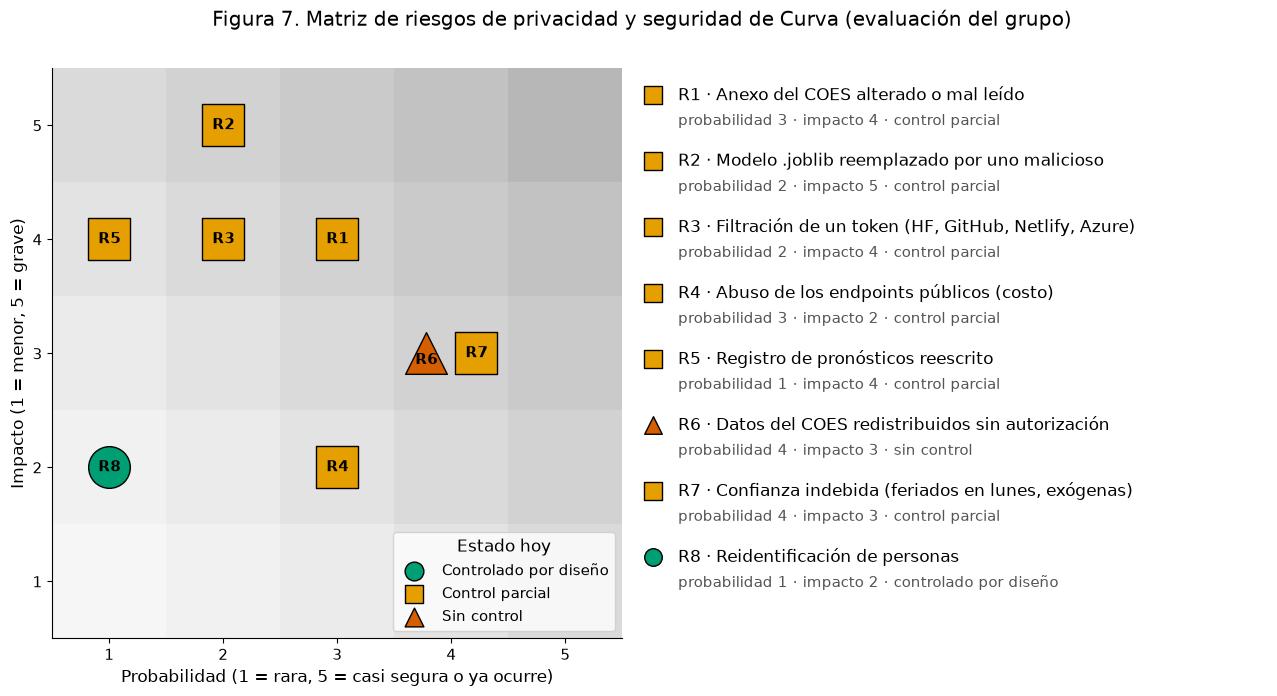

In [16]:
# Nuestra evaluación cualitativa: probabilidad e impacto de 1 (bajo) a 5 (alto), con los controles de hoy
RIESGOS = pd.DataFrame([
    ("R1", "Anexo del COES alterado o mal leído", 3, 4, "Parcial"),
    ("R2", "Modelo .joblib reemplazado por uno malicioso", 2, 5, "Parcial"),
    ("R3", "Filtración de un token (HF, GitHub, Netlify, Azure)", 2, 4, "Parcial"),
    ("R4", "Abuso de los endpoints públicos (costo)", 3, 2, "Parcial"),
    ("R5", "Registro de pronósticos reescrito", 1, 4, "Parcial"),
    ("R6", "Datos del COES redistribuidos sin autorización", 4, 3, "Falta"),
    ("R7", "Confianza indebida (feriados en lunes, exógenas)", 4, 3, "Parcial"),
    ("R8", "Reidentificación de personas", 1, 2, "Controlado"),
], columns=["id", "riesgo", "probabilidad", "impacto", "control"])
ESTILO = {"Controlado": ("#009E73", "o", "Controlado por diseño"), "Parcial": ("#E69F00", "s", "Control parcial"),
          "Falta": ("#D55E00", "^", "Sin control")}
DESPLAZA = {"R6": -0.22, "R7": 0.22}  # comparten casilla

fig, (eje, lista) = plt.subplots(1, 2, figsize=(13, 6.6), gridspec_kw={"width_ratios": [1, 1.1]})
nivel = np.add.outer(np.arange(1, 6), np.arange(1, 6))  # impacto + probabilidad: de 2 a 10
eje.imshow(nivel, origin="lower", extent=[0.5, 5.5, 0.5, 5.5], cmap="Greys", alpha=0.35, vmin=0, vmax=12)
for control, (color, marca, nombre) in ESTILO.items():
    sel = RIESGOS[RIESGOS["control"] == control]
    x = sel["probabilidad"] + sel["id"].map(DESPLAZA).fillna(0)
    eje.scatter(x, sel["impacto"], s=900, color=color, marker=marca, edgecolor="black", label=nombre, zorder=3)
    for ident, xi, yi in zip(sel["id"], x, sel["impacto"]):
        eje.annotate(ident, (xi, yi - (0.06 if marca == "^" else 0)), ha="center", va="center", fontsize=10.5,
                     fontweight="bold", zorder=4)
eje.set(xlim=(0.5, 5.5), ylim=(0.5, 5.5), xticks=range(1, 6), yticks=range(1, 6),
        xlabel="Probabilidad (1 = rara, 5 = casi segura o ya ocurre)", ylabel="Impacto (1 = menor, 5 = grave)")
eje.legend(loc="lower right", title="Estado hoy", markerscale=0.45)
lista.axis("off")
for k, r in enumerate(RIESGOS.itertuples()):
    color, marca, _ = ESTILO[r.control]
    y = 0.95 - k * 0.115
    lista.scatter(0.02, y, s=160, color=color, marker=marca, edgecolor="black", transform=lista.transAxes, clip_on=False)
    lista.text(0.06, y, f"{r.id} · {r.riesgo}", transform=lista.transAxes, va="center", fontsize=12.5)
    lista.text(0.06, y - 0.045, f"probabilidad {r.probabilidad} · impacto {r.impacto} · {ESTILO[r.control][2].lower()}",
               transform=lista.transAxes, va="center", fontsize=11, color="#555555")
fig.suptitle("Figura 7. Matriz de riesgos de privacidad y seguridad de Curva (evaluación del grupo)", y=1.0)
plt.tight_layout()
plt.show()

#### Lectura del gráfico

- **Los dos riesgos más probables ya ocurren o ya ocurrieron:** la redistribución de datos del COES (R6) sucede hoy,
  mientras el dataset sea público, y la confianza indebida (R7) se materializó el 29 de junio. Son los primeros que
  atenderíamos, y ninguno exige trabajo técnico difícil: una autorización (o volver privado el dataset) y una regla de
  revisión manual de los feriados en lunes.
- **El de mayor impacto es la cadena de suministro del modelo (R2):** poco probable mientras el token de escritura esté
  bien guardado, pero si pasa, ejecuta código. Se cierra casi del todo con el formato `.ubj` y la huella del manifiesto
  fijada dentro de la imagen.
- **Ningún riesgo de privacidad de personas es relevante a este nivel de agregación (R8)**, y es el único controlado por
  diseño. El trabajo de privacidad de Curva es, en realidad, de **seguridad e integridad**: que el dato de entrada, el
  modelo y el registro sean los que dicen ser.

## 3.6 ¿Cómo proteger los datos? Las medidas que implementaríamos

| Medida | Estado en Curva | Qué implementaríamos |
|---|---|---|
| **Anonimización y seudonimización** | Los datos ya son agregados por área: anónimos por construcción | Si bajamos a subestación: regla 15/15 y disociación de los códigos de subestación y de usuario libre; en los eventos, cambiar el nombre del usuario libre por su tipo («usuario libre minero») antes de publicar |
| **Control de acceso** | Dataset e imagen públicos y API sin autenticación (decisión del dueño, para mostrar la app); los scripts de despliegue rechazan otra suscripción de Azure y las cuentas de trabajo | Dataset privado con un token de solo lectura guardado como secreto; tokens de grano fino; segundo factor en Hugging Face, GitHub, Netlify y Azure; ramas protegidas en GitHub |
| **Cifrado** | HTTPS en la web, la API, el Hub y la descarga del COES | Tokens en un llavero cifrado (el ejemplo de `despliegue/README.md` lee el de Hugging Face de una variable universal de fish, que se guarda en texto plano en el perfil del usuario); cifrado del disco de la laptop donde corre la corrida diaria |
| **Minimización** | El paquete de la app lleva solo lo que necesita (sin el bronze, sin los pesos de Chronos-2, sin la demanda en vivo cruda); sin cookies ni analítica | Publicar solo las series que la app muestra; en vez de los eventos con nombres, publicar la variable ya calculada (fallas en curso por periodo) |
| **Integridad y protección de la información sensible** | sha256 en cada capa y en el manifiesto; registro que solo crece; validación del anexo | Huella del manifiesto dentro de la imagen y revisión fijada del dataset; modelos en `.ubj`; huella diaria del registro fuera del dataset; control de traspasos entre áreas |
| **Respuesta a incidentes** | No hay un procedimiento escrito | Uno corto: revocar los tokens, volver a una revisión conocida del dataset y a una imagen `sha-<commit>`, y avisar en la app. Si algún día hubiera datos personales, notificar a la Autoridad en 48 horas |

# 4. Conclusiones y recomendaciones

## Qué aprendimos del comportamiento del modelo

1. **Pronostica como un programador con experiencia.** A 1 h, con la demanda de ahora; a 24 h, con la de hace una
   semana a la misma hora y la hora del día. La demanda reciente y el calendario explican el 93.8 % y el 86.3 % del
   movimiento del pronóstico; clima, El Niño y fallas, el 3.2 % y el 8.4 %.
2. **Su punto ciego tiene nombre: los feriados que caen en lunes.** El peor error de 2026 (776 MW, el 29 de junio) sale
   de restar 558 MW de feriado sobre un punto de partida que ya era de domingo.
3. **SHAP, la permutación y LIME coinciden en lo esencial, pero solo SHAP es exacto.** LIME, con un R² local de 0.35 a
   0.38, no reproduce el pronóstico que explica y atribuye peso a variables sin sentido en 2026 (la cuarentena).
4. **El Niño mueve poco y en la dirección del pasado:** lo que permite al modelo aguantar 2026 es la escala (la media de
   24 h), no las variables de El Niño.

## ¿Es explicable y confiable?

- **Explicable, sí.** Cada pronóstico se descompone de forma exacta en MW, en variables y familias que el negocio
  reconoce, y las explicaciones globales tienen sentido operativo.
- **Confiable en días normales, sí:** le gana a la mejor referencia ingenua en las seis combinaciones de área y
  horizonte, con un error de 1.2 % a 2.9 % de la demanda. **En feriados que caen en lunes, no;** y con exógenas fuera de
  rango, con cuidado. Un sistema confiable no es el que nunca falla, sino el que avisa cuándo desconfiar: eso es lo que
  agregan la explicación y los avisos que proponemos.
- **Privacidad y seguridad:** el sistema no trata datos personales y la reidentificación a nivel de área es
  prácticamente imposible. Sus riesgos reales son de integridad (el anexo, los modelos y el registro), de credenciales y
  costo, y de cumplimiento de las condiciones del COES.

## Qué mejoraríamos antes de producción, en orden

1. **Feriados:** una variable «el día anterior fue domingo o feriado» y, mientras tanto, revisión manual de los feriados
   que caen en lunes.
2. **Datos del COES:** pedir autorización escrita o volver privado el dataset, y quitar los nombres de usuarios libres.
3. **Cadena de suministro del modelo:** `.ubj` en vez de `.joblib`, revisión del dataset fijada y huella del manifiesto
   dentro de la imagen.
4. **Integridad de la entrada:** detectar los traspasos de media hora entre áreas en la validación del anexo.
5. **Credenciales:** tokens de grano fino, segundo factor y un llavero cifrado.
6. **Costo y disponibilidad:** límite de pedidos por IP para los POST y apagado automático al pasar el presupuesto.
7. **Registro:** huella diaria del registro de pronósticos fuera del dataset.
8. **Monitoreo y transparencia:** aviso de deriva cuando la temperatura o el ICEN salen del rango de entrenamiento, y la
   explicación SHAP de cada pronóstico visible en la app (en la pantalla «Detalle»).

**Límites.** SHAP explica el modelo, no el sistema eléctrico: dice en qué se apoya el XGBoost, no qué causa la demanda.
La explicación global usa una muestra de 2,000 periodos por área y horizonte; los tres casos se eligieron con una regla
fija, pero son tres: ilustran, no prueban. La matriz de riesgos es una evaluación cualitativa del grupo, y la lectura
del marco legal es nuestra: conviene que la valide un especialista.

## Referencias

- Congreso de la República (2011). *Ley N.° 29733, Ley de Protección de Datos Personales*. El Peruano, 3 de julio de
  2011. <https://www.leyes.congreso.gob.pe/Documentos/Leyes/29733.pdf>
- Ministerio de Justicia y Derechos Humanos (2024). *D. S. N.° 016-2024-JUS, Reglamento de la Ley N.° 29733*.
  <https://www.gob.pe/institucion/anpd/normas-legales/6554453-16-2024-jus>; resumen de los cambios en El Peruano:
  <https://www.elperuano.pe/noticia/259141--peru-fortalece-la-proteccion-de-datos-estos-son-los-principales-cambios-del-nuevo-reglamento>
- Presidencia del Consejo de Ministros (2025). *D. S. N.° 115-2025-PCM, Reglamento de la Ley N.° 31814, que promueve el
  uso de la inteligencia artificial*. <https://busquedas.elperuano.pe/dispositivo/NL/2436426-1>
- COES (2025). *Términos y condiciones del portal*. <https://www.coes.org.pe/Portal/Organizacion/TerminosyCondiciones>
- OWASP (2023). *Machine Learning Security Top Ten* (borrador).
  <https://owasp.org/www-project-machine-learning-security-top-ten/>
- NIST (2023). *Artificial Intelligence Risk Management Framework (AI RMF 1.0)*, NIST AI 100-1.
  <https://doi.org/10.6028/NIST.AI.100-1>
- Lundberg, S. y Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS.
  <https://arxiv.org/abs/1705.07874>
- Ribeiro, M. T., Singh, S. y Guestrin, C. (2016). *«Why Should I Trust You?»: Explaining the Predictions of Any
  Classifier*. KDD. <https://arxiv.org/abs/1602.04938>
- joblib. *Persistence* (advertencia de seguridad). <https://joblib.readthedocs.io/en/stable/persistence.html>
- XGBoost. *Introduction to Model IO*. <https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html>
- Hugging Face. *Pickle Scanning*. <https://huggingface.co/docs/hub/security-pickle>
- Molina-Markham, A., Shenoy, P., Fu, K., Cecchet, E. e Irwin, D. (2010). *Private Memoirs of a Smart Meter*. BuildSys.
  <https://rts.cs.umass.edu/papers/pdf/buildsys10.pdf>
- Emmett Institute (UCLA) y CLEE (UC Berkeley) (2021). *Data Access for a Decarbonized Grid* (sobre la regla 15/15 de la
  CPUC, decisión D.14-05-016).
  <https://www.law.berkeley.edu/wp-content/uploads/2021/02/Data-Access-for-a-Decarbonized-Grid-February-2021.pdf>
- Proyecto: `notebooks/05_sein_explicabilidad.ipynb`, `despliegue/README.md` y `src/tetouan_power_forecast/en_vivo.py`
  del repositorio.